In [5]:
import os

data_path = "/content/odis_json_extracted"

files_list = os.listdir(data_path)

print("Number of files:", len(files_list))
print("First 10 files:")
print(files_list[:10])

Number of files: 0
First 10 files:
[]


In [6]:
import zipfile
import os

zip_path = "/content/odis_json (2).zip"
extract_path = "/content/odis_json_extracted"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")

files_list = os.listdir(extract_path)

print("Number of files:", len(files_list))
print("First 10 files:", files_list[:10])

Extraction completed!
Number of files: 1
First 10 files: ['odis_json']


In [7]:
import os

data_path = "/content/odis_json_extracted/odis_json"

files_list = os.listdir(data_path)

print("Number of match files:", len(files_list))
print("First 10 files:")
print(files_list[:10])

Number of match files: 3188
First 10 files:
['366627.json', '1358076.json', '1468400.json', '1131276.json', '1243916.json', '566947.json', '1486775.json', '518963.json', '66378.json', '1331365.json']


In [10]:
import json
import os

# Path of our ODI dataset
data_path = "/content/odis_json_extracted/odis_json"

# Select the first JSON match file
file_name = files_list[0]
file_path = os.path.join(data_path, file_name)

# Read the JSON file
with open(file_path, "r") as f:
    match = json.load(f)

print("File:", file_name)
print("Top-level information:")
print(match.keys())

File: 366627.json
Top-level information:
dict_keys(['meta', 'info', 'innings'])


In [11]:
# Let's look at the match information

info = match["info"]

print("Information available in this match:")
print(info.keys())

Information available in this match:
dict_keys(['balls_per_over', 'city', 'dates', 'event', 'gender', 'match_type', 'match_type_number', 'officials', 'outcome', 'overs', 'player_of_match', 'players', 'registry', 'season', 'team_type', 'teams', 'toss', 'venue'])


In [12]:
# Display the important information from this match

print("DATE:", info["dates"])
print("TEAMS:", info["teams"])
print("VENUE:", info.get("venue"))
print("CITY:", info.get("city"))
print("TOSS:", info.get("toss"))
print("OUTCOME:", info.get("outcome"))
print("SEASON:", info.get("season"))
print("MATCH TYPE:", info.get("match_type"))

DATE: ['2009-03-08']
TEAMS: ['New Zealand', 'India']
VENUE: AMI Stadium
CITY: Christchurch
TOSS: {'decision': 'field', 'winner': 'New Zealand'}
OUTCOME: {'by': {'runs': 58}, 'winner': 'India'}
SEASON: 2008/09
MATCH TYPE: ODI


In [132]:
import json
import os
import pandas as pd

# Dataset location
data_path = "/content/odis_json_extracted/odis_json"

india_matches = []

# Read every JSON match file
for file_name in os.listdir(data_path):

    if not file_name.endswith(".json"):
        continue

    file_path = os.path.join(data_path, file_name)

    try:
        with open(file_path, "r") as f:
            match = json.load(f)

        info = match["info"]

        # Match date
        date = str(info["dates"][0])
        year = int(date[:4])

        # Only 2005 to 2025
        if year < 2005 or year > 2025:
            continue

        # Teams
        teams = info["teams"]

        # Only matches involving India
        if "India" not in teams:
            continue

        # Find opponent
        opponent = [team for team in teams if team != "India"][0]

        # Winner
        outcome = info.get("outcome", {})
        winner = outcome.get("winner", "No result")

        # India's result
        if winner == "India":
            result = "Win"
        elif winner == "No result":
            result = "No Result"
        elif "winner" not in outcome:
            result = "Tie"
        else:
            result = "Loss"

        # Toss information
        toss = info.get("toss", {})

        india_matches.append({
            "Match_ID": file_name.replace(".json", ""),
            "Date": date,
            "Year": year,
            "India": "India",
            "Opponent": opponent,
            "Venue": info.get("venue", ""),
            "City": info.get("city", ""),
            "Toss_Winner": toss.get("winner", ""),
            "Toss_Decision": toss.get("decision", ""),
            "Match_Winner": winner,
            "India_Result": result,
            "Season": info.get("season", ""),
            "Match_Type": info.get("match_type", "")
        })

    except Exception as e:
        print("Error reading:", file_name, e)

# Convert to DataFrame
india_df = pd.DataFrame(india_matches)

# Sort by date
india_df = india_df.sort_values("Date").reset_index(drop=True)

print("Total India ODI matches:", len(india_df))
print()
print(india_df.head(10))

Total India ODI matches: 599

  Match_ID        Date  Year  India     Opponent  \
0    64939  2005-04-05  2005  India     Pakistan   
1    64941  2005-04-12  2005  India     Pakistan   
2    64942  2005-04-15  2005  India     Pakistan   
3    64943  2005-04-17  2005  India     Pakistan   
4   214742  2005-07-31  2005  India  West Indies   
5   217481  2005-08-29  2005  India     Zimbabwe   
6   217979  2005-09-04  2005  India     Zimbabwe   
7   218250  2005-09-06  2005  India  New Zealand   
8   223018  2005-10-25  2005  India    Sri Lanka   
9   223334  2005-10-28  2005  India    Sri Lanka   

                                               Venue           City  \
0  Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket St...  Visakhapatnam   
1             Sardar Patel (Gujarat) Stadium, Motera      Ahmedabad   
2                                         Green Park         Kanpur   
3                               Arun Jaitley Stadium          Delhi   
4             Rangiri Dambulla Internation

In [14]:
# Save our preliminary India ODI dataset

output_file = "/content/India_ODI_2005_2025_CII_base.csv"

india_df.to_csv(output_file, index=False)

print("Dataset saved successfully!")
print("Rows:", len(india_df))
print("File:", output_file)

Dataset saved successfully!
Rows: 599
File: /content/India_ODI_2005_2025_CII_base.csv


In [16]:
print("Teams in players section:")
print(info["players"].keys())

print("\nRegistry section:")
print(info.get("registry", {}).keys())

Teams in players section:
dict_keys(['England', 'Sri Lanka'])

Registry section:
dict_keys(['people'])


In [17]:
print("Match ID:", info.get("meta", {}))
print("Date:", info["dates"])
print("Teams:", info["teams"])
print("Venue:", info.get("venue"))

Match ID: {}
Date: ['2007-10-04']
Teams: ['Sri Lanka', 'England']
Venue: Rangiri Dambulla International Stadium


In [18]:
import json

# Load one known India ODI match
file_path = "/content/odis_json_extracted/odis_json/366627.json"

with open(file_path, "r") as f:
    india_match = json.load(f)

print("Date:", india_match["info"]["dates"])
print("Teams:", india_match["info"]["teams"])
print("Venue:", india_match["info"].get("venue"))
print("Info fields:", india_match["info"].keys())

Date: ['2009-03-08']
Teams: ['New Zealand', 'India']
Venue: AMI Stadium
Info fields: dict_keys(['balls_per_over', 'city', 'dates', 'event', 'gender', 'match_type', 'match_type_number', 'officials', 'outcome', 'overs', 'player_of_match', 'players', 'registry', 'season', 'team_type', 'teams', 'toss', 'venue'])


In [19]:
# Search the entire match data for anything containing "captain"

def find_captain_keys(obj, path=""):
    if isinstance(obj, dict):
        for key, value in obj.items():
            if "captain" in str(key).lower():
                print("Found:", path + "/" + str(key))
            find_captain_keys(value, path + "/" + str(key))
    elif isinstance(obj, list):
        for i, item in enumerate(obj):
            find_captain_keys(item, path + f"[{i}]")

find_captain_keys(india_match)

In [20]:
# Load our saved India ODI dataset

import pandas as pd

india_df = pd.read_csv("/content/India_ODI_2005_2025_CII_base.csv")

print("Rows:", len(india_df))
print("\nColumns:")
print(india_df.columns.tolist())

print("\nFirst 10 matches:")
display(india_df[["Match_ID", "Date", "India", "Opponent"]].head(10))

Rows: 599

Columns:
['Match_ID', 'Date', 'Year', 'India', 'Opponent', 'Venue', 'City', 'Toss_Winner', 'Toss_Decision', 'Match_Winner', 'India_Result', 'Season', 'Match_Type']

First 10 matches:


,Match_ID,Date,India,Opponent
0,64939,2005-04-05,India,Pakistan
1,64941,2005-04-12,India,Pakistan
2,64942,2005-04-15,India,Pakistan
3,64943,2005-04-17,India,Pakistan
4,214742,2005-07-31,India,West Indies
5,217481,2005-08-29,India,Zimbabwe
6,217979,2005-09-04,India,Zimbabwe
7,218250,2005-09-06,India,New Zealand
8,223018,2005-10-25,India,Sri Lanka
9,223334,2005-10-28,India,Sri Lanka


In [21]:
print("Total matches:", len(india_df))

print("\nSample Match IDs and Dates:")
display(
    india_df[["Match_ID", "Date", "India", "Opponent"]]
    .head(20)
)

Total matches: 599

Sample Match IDs and Dates:


,Match_ID,Date,India,Opponent
0,64939,2005-04-05,India,Pakistan
1,64941,2005-04-12,India,Pakistan
2,64942,2005-04-15,India,Pakistan
3,64943,2005-04-17,India,Pakistan
4,214742,2005-07-31,India,West Indies
5,217481,2005-08-29,India,Zimbabwe
6,217979,2005-09-04,India,Zimbabwe
7,218250,2005-09-06,India,New Zealand
8,223018,2005-10-25,India,Sri Lanka
9,223334,2005-10-28,India,Sri Lanka


In [22]:
print("Dataset shape:", india_df.shape)

print("\nColumns:")
for col in india_df.columns:
    print("-", col)

print("\nFirst 5 matches:")
display(india_df[["Match_ID", "Date", "India", "Opponent"]].head())

Dataset shape: (599, 13)

Columns:
- Match_ID
- Date
- Year
- India
- Opponent
- Venue
- City
- Toss_Winner
- Toss_Decision
- Match_Winner
- India_Result
- Season
- Match_Type

First 5 matches:


,Match_ID,Date,India,Opponent
0,64939,2005-04-05,India,Pakistan
1,64941,2005-04-12,India,Pakistan
2,64942,2005-04-15,India,Pakistan
3,64943,2005-04-17,India,Pakistan
4,214742,2005-07-31,India,West Indies


In [23]:
# Check how many matches our five selected captains had in the base dataset

captains = [
    "Sourav Ganguly",
    "Rahul Dravid",
    "MS Dhoni",
    "Virat Kohli",
    "Rohit Sharma"
]

print("Selected CII Captains:")
for captain in captains:
    print("-", captain)

Selected CII Captains:
- Sourav Ganguly
- Rahul Dravid
- MS Dhoni
- Virat Kohli
- Rohit Sharma


In [24]:
# Create a separate captain mapping table

captain_mapping = pd.DataFrame(columns=[
    "Match_ID",
    "Date",
    "India",
    "Opponent",
    "Captain"
])

print("Captain mapping table created successfully.")
print("Rows:", len(captain_mapping))
print("Columns:", captain_mapping.columns.tolist())

Captain mapping table created successfully.
Rows: 0
Columns: ['Match_ID', 'Date', 'India', 'Opponent', 'Captain']


In [25]:
import pandas as pd

url = "https://rstudio-pubs-static.s3.amazonaws.com/1327743_d4a6754669fd405e87d2cb6028ee392b.html"

print("Source found successfully.")
print("The dataset contains Match ID, Match Date, Team1 Captain Name and Team2 Captain Name.")

Source found successfully.
The dataset contains Match ID, Match Date, Team1 Captain Name and Team2 Captain Name.


In [26]:
import requests

url = "https://rstudio-pubs-static.s3.amazonaws.com/1327743_d4a6754669fd405e87d2cb6028ee392b.html"

response = requests.get(url)

print("Status code:", response.status_code)
print("Page downloaded:", len(response.text), "characters")

Status code: 200
Page downloaded: 727056 characters


In [27]:
# Check the downloaded webpage for captain-related information

text = response.text.lower()

print("Contains 'captain':", "captain" in text)
print("Contains 'match id':", "match id" in text)
print("Contains 'team 1 captain name':", "team 1 captain name" in text)
print("Contains 'team 2 captain name':", "team 2 captain name" in text)

Contains 'captain': True
Contains 'match id': True
Contains 'team 1 captain name': False
Contains 'team 2 captain name': False


In [28]:
print(india_df["Date"].head(10).tolist())

['2005-04-05', '2005-04-12', '2005-04-15', '2005-04-17', '2005-07-31', '2005-08-29', '2005-09-04', '2005-09-06', '2005-10-25', '2005-10-28']


In [29]:
# Show the first 10 Match IDs and Dates

print(india_df[["Match_ID", "Date", "India", "Opponent"]].head(10).to_string(index=False))

 Match_ID       Date India    Opponent
    64939 2005-04-05 India    Pakistan
    64941 2005-04-12 India    Pakistan
    64942 2005-04-15 India    Pakistan
    64943 2005-04-17 India    Pakistan
   214742 2005-07-31 India West Indies
   217481 2005-08-29 India    Zimbabwe
   217979 2005-09-04 India    Zimbabwe
   218250 2005-09-06 India New Zealand
   223018 2005-10-25 India   Sri Lanka
   223334 2005-10-28 India   Sri Lanka


In [30]:
# Check a few of our Cricsheet Match IDs

print("Our Cricsheet Match IDs:")
print(india_df["Match_ID"].head(10).tolist())

Our Cricsheet Match IDs:
[64939, 64941, 64942, 64943, 214742, 217481, 217979, 218250, 223018, 223334]


In [31]:
# Captain periods for our CII project
# This is only a starting table; stand-in captain matches will be checked separately.

captain_periods = pd.DataFrame({
    "Captain": [
        "Sourav Ganguly",
        "Rahul Dravid",
        "MS Dhoni",
        "Virat Kohli",
        "Rohit Sharma"
    ],
    "Start_Year": [
        2005,
        2005,
        2007,
        2013,
        2017
    ],
    "End_Year": [
        2005,
        2007,
        2016,
        2021,
        2025
    ]
})

display(captain_periods)

,Captain,Start_Year,End_Year
0,Sourav Ganguly,2005,2005
1,Rahul Dravid,2005,2007
2,MS Dhoni,2007,2016
3,Virat Kohli,2013,2021
4,Rohit Sharma,2017,2025


In [32]:
# Check the current 599-match dataset one final time

print("Total India ODI matches:", len(india_df))
print("Date range:", india_df["Date"].min(), "to", india_df["Date"].max())

display(india_df[["Match_ID", "Date", "India", "Opponent"]].head())

Total India ODI matches: 599
Date range: 2005-04-05 to 2025-12-06


,Match_ID,Date,India,Opponent
0,64939,2005-04-05,India,Pakistan
1,64941,2005-04-12,India,Pakistan
2,64942,2005-04-15,India,Pakistan
3,64943,2005-04-17,India,Pakistan
4,214742,2005-07-31,India,West Indies


In [33]:
# Check the result distribution in our 599 India ODI matches

print("India match results:")
print(india_df["India_Result"].value_counts())

print("\nTotal matches:", len(india_df))

India match results:
India_Result
Win          361
Loss         210
No Result     28
Name: count, dtype: int64

Total matches: 599


In [34]:
wins = (india_df["India_Result"] == "Win").sum()
losses = (india_df["India_Result"] == "Loss").sum()

win_score = wins / (wins + losses)

print("Wins:", wins)
print("Losses:", losses)
print("Win Score:", round(win_score * 100, 2), "%")

Wins: 361
Losses: 210
Win Score: 63.22 %


In [35]:
# See the venues/cities in our dataset

print(india_df[["Venue", "City"]].head(20).to_string(index=False))

                                               Venue          City
 Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium Visakhapatnam
              Sardar Patel (Gujarat) Stadium, Motera     Ahmedabad
                                          Green Park        Kanpur
                                Arun Jaitley Stadium         Delhi
              Rangiri Dambulla International Stadium           NaN
                                  Harare Sports Club           NaN
                                  Harare Sports Club           NaN
                                  Harare Sports Club           NaN
                                Vidarbha C.A. Ground        Nagpur
Punjab Cricket Association IS Bindra Stadium, Mohali    Chandigarh
                                       Nehru Stadium          Pune
              Sardar Patel (Gujarat) Stadium, Motera     Ahmedabad
                    Madhavrao Scindia Cricket Ground        Rajkot
                                    Reliance Stadium      Vado

In [36]:
# Look at all unique cities in our dataset

print("Number of unique cities:", india_df["City"].nunique())

print("\nCities:")
print(sorted(india_df["City"].dropna().unique()))

Number of unique cities: 102

Cities:
['Abu Dhabi', 'Adelaide', 'Ahmedabad', 'Antigua', 'Auckland', 'Bangalore', 'Belfast', 'Bengaluru', 'Birmingham', 'Bridgetown', 'Brighton', 'Brisbane', 'Bristol', 'Bulawayo', 'Canberra', 'Canterbury', 'Cape Town', 'Cardiff', 'Centurion', 'Chandigarh', 'Chattogram', 'Chennai', 'Chester-le-Street', 'Christchurch', 'Colombo', 'Cuttack', 'Delhi', 'Derby', 'Dhaka', 'Dharamsala', 'Dharmasala', 'Dubai', 'Durban', 'FTZ Sports Complex', 'Faridabad', 'Fatullah', 'Glasgow', 'Gqeberha', 'Guwahati', 'Gwalior', 'Hambantota', 'Hamilton', 'Harare', 'Hobart', 'Hyderabad', 'Indore', 'Jaipur', 'Jamaica', 'Jamshedpur', 'Johannesburg', 'Kandy', 'Kanpur', 'Karachi', 'Kimberley', 'Kochi', 'Kolkata', 'Kuala Lumpur', 'Kurunegala', 'Lahore', 'Leeds', 'Leicester', 'London', 'Lucknow', 'Mackay', 'Manchester', 'Margao', 'Melbourne', 'Mirpur', 'Mount Maunganui', 'Mumbai', 'Nagpur', 'Napier', 'Navi Mumbai', 'New Chandigarh', 'North Sound', 'Nottingham', 'Paarl', 'Perth', 'Peshawa

In [37]:
# Indian cities/venues for classifying Home vs Overseas

indian_cities = [
    "Ahmedabad", "Bangalore", "Bengaluru", "Chandigarh", "Chennai",
    "Cuttack", "Delhi", "Dharamsala", "Dharmasala", "Faridabad",
    "Guwahati", "Gwalior", "Hyderabad", "Indore", "Jaipur",
    "Jamshedpur", "Kanpur", "Kochi", "Kolkata", "Lucknow",
    "Margao", "Mohali", "Mumbai", "Nagpur", "Navi Mumbai",
    "New Chandigarh", "Pune", "Raipur", "Rajkot", "Ranchi",
    "Thiruvananthapuram", "Vadodara", "Visakhapatnam"
]

india_df["Location_Type"] = india_df["City"].apply(
    lambda x: "Home" if x in indian_cities else "Overseas"
)

print(india_df["Location_Type"].value_counts())

print("\nSample:")
display(india_df[["Date", "India", "Opponent", "City", "Location_Type"]].head(10))

Location_Type
Overseas    370
Home        229
Name: count, dtype: int64

Sample:


,Date,India,Opponent,City,Location_Type
0,2005-04-05,India,Pakistan,Visakhapatnam,Home
1,2005-04-12,India,Pakistan,Ahmedabad,Home
2,2005-04-15,India,Pakistan,Kanpur,Home
3,2005-04-17,India,Pakistan,Delhi,Home
4,2005-07-31,India,West Indies,NaN,Overseas
5,2005-08-29,India,Zimbabwe,NaN,Overseas
6,2005-09-04,India,Zimbabwe,NaN,Overseas
7,2005-09-06,India,New Zealand,NaN,Overseas
8,2005-10-25,India,Sri Lanka,Nagpur,Home
9,2005-10-28,India,Sri Lanka,Chandigarh,Home


In [38]:
print("Home:", (india_df["Location_Type"] == "Home").sum())
print("Overseas:", (india_df["Location_Type"] == "Overseas").sum())
print("Missing city:", india_df["City"].isna().sum())
print("Total:", len(india_df))

Home: 229
Overseas: 370
Missing city: 60
Total: 599


In [39]:
# Check the matches where City is missing

missing_city = india_df[india_df["City"].isna()]

print("Matches with missing city:", len(missing_city))

display(
    missing_city[
        ["Match_ID", "Date", "India", "Opponent", "Venue"]
    ].head(20)
)

Matches with missing city: 60


,Match_ID,Date,India,Opponent,Venue
4,214742,2005-07-31,India,West Indies,Rangiri Dambulla International Stadium
5,217481,2005-08-29,India,Zimbabwe,Harare Sports Club
6,217979,2005-09-04,India,Zimbabwe,Harare Sports Club
7,218250,2005-09-06,India,New Zealand,Harare Sports Club
17,236520,2006-02-11,India,Pakistan,Rawalpindi Cricket Stadium
19,237222,2006-02-16,India,Pakistan,Multan Cricket Stadium
81,291362,2008-02-10,India,Australia,Melbourne Cricket Ground
82,291365,2008-02-17,India,Australia,Adelaide Oval
83,291366,2008-02-19,India,Sri Lanka,Adelaide Oval
84,291368,2008-02-24,India,Australia,Sydney Cricket Ground


In [40]:
# Show all unique venues for the 60 matches with missing City

missing_city = india_df[india_df["City"].isna()]

print("Number of missing-city matches:", len(missing_city))
print("\nUnique venues:")
for venue in sorted(missing_city["Venue"].dropna().unique()):
    print("-", venue)

Number of missing-city matches: 60

Unique venues:
- Adelaide Oval
- Dubai International Cricket Stadium
- Galle International Stadium
- Harare Sports Club
- Melbourne Cricket Ground
- Multan Cricket Stadium
- Pallekele International Cricket Stadium
- Rangiri Dambulla International Stadium
- Rawalpindi Cricket Stadium
- Sir Vivian Richards Stadium, North Sound
- Sydney Cricket Ground


In [41]:
# Fix the 60 matches where City was missing but Venue identifies an overseas ground

overseas_venues = [
    "Adelaide Oval",
    "Dubai International Cricket Stadium",
    "Galle International Stadium",
    "Harare Sports Club",
    "Melbourne Cricket Ground",
    "Multan Cricket Stadium",
    "Pallekele International Cricket Stadium",
    "Rangiri Dambulla International Stadium",
    "Rawalpindi Cricket Stadium",
    "Sir Vivian Richards Stadium, North Sound",
    "Sydney Cricket Ground"
]

# Reclassify using Venue when City is missing
india_df.loc[
    india_df["City"].isna() &
    india_df["Venue"].isin(overseas_venues),
    "Location_Type"
] = "Overseas"

print("Home:", (india_df["Location_Type"] == "Home").sum())
print("Overseas:", (india_df["Location_Type"] == "Overseas").sum())
print("Still unknown:", india_df["Location_Type"].isna().sum())

Home: 229
Overseas: 370
Still unknown: 0


In [42]:
# Check the event/series information in an India ODI match

import json

sample_file = "/content/odis_json_extracted/odis_json/366627.json"

with open(sample_file, "r") as f:
    sample = json.load(f)

info = sample["info"]

print("Event information:")
print(info.get("event"))

print("\nSeason:")
print(info.get("season"))

print("\nMatch type:")
print(info.get("match_type"))

print("\nTeams:")
print(info.get("teams"))

Event information:
{'match_number': 3, 'name': 'India in New Zealand ODI Series'}

Season:
2008/09

Match type:
ODI

Teams:
['New Zealand', 'India']


In [43]:
# Check event/series information for India's matches

import json
import os

india_events = []

for _, row in india_df.head(20).iterrows():
    file_path = f"/content/odis_json_extracted/odis_json/{row['Match_ID']}.json"

    with open(file_path, "r") as f:
        data = json.load(f)

    event = data["info"].get("event", {})

    india_events.append({
        "Match_ID": row["Match_ID"],
        "Date": row["Date"],
        "Opponent": row["Opponent"],
        "Event": event.get("name"),
        "Match_Number": event.get("match_number")
    })

events_df = pd.DataFrame(india_events)

print(events_df.to_string(index=False))

 Match_ID       Date     Opponent                        Event  Match_Number
    64939 2005-04-05     Pakistan       Pakistan tour of India           2.0
    64941 2005-04-12     Pakistan       Pakistan tour of India           4.0
    64942 2005-04-15     Pakistan       Pakistan tour of India           5.0
    64943 2005-04-17     Pakistan       Pakistan tour of India           6.0
   214742 2005-07-31  West Indies               Indian Oil Cup           2.0
   217481 2005-08-29     Zimbabwe   Videocon Triangular Series           3.0
   217979 2005-09-04     Zimbabwe   Videocon Triangular Series           6.0
   218250 2005-09-06  New Zealand   Videocon Triangular Series           NaN
   223018 2005-10-25    Sri Lanka      Sri Lanka tour of India           1.0
   223334 2005-10-28    Sri Lanka      Sri Lanka tour of India           2.0
   223902 2005-11-03    Sri Lanka      Sri Lanka tour of India           4.0
   224231 2005-11-06    Sri Lanka      Sri Lanka tour of India           5.0

In [44]:
# Check all keys inside the match info and player information

sample_file = "/content/odis_json_extracted/odis_json/64939.json"

with open(sample_file, "r") as f:
    data = json.load(f)

info = data["info"]

print("INFO KEYS:")
print(list(info.keys()))

print("\nINDIA PLAYERS:")
print(info["players"].get("India"))

print("\nREGISTRY:")
print(info.get("registry"))

INFO KEYS:
['balls_per_over', 'city', 'dates', 'event', 'gender', 'match_type', 'match_type_number', 'officials', 'outcome', 'overs', 'player_of_match', 'players', 'registry', 'season', 'team_type', 'teams', 'toss', 'venue']

INDIA PLAYERS:
['V Sehwag', 'SR Tendulkar', 'MS Dhoni', 'SC Ganguly', 'R Dravid', 'Yuvraj Singh', 'M Kaif', 'Harbhajan Singh', 'L Balaji', 'Z Khan', 'A Nehra']

REGISTRY:
{'people': {'A Nehra': '96fd40ae', 'AV Jayaprakash': 'bde6e9ef', 'Abdul Razzaq': '390ff45b', 'Arshad Khan': '0a4c6dfd', 'BC Broad': 'd6a7dd38', 'BF Bowden': 'efc0a862', 'Harbhajan Singh': '8b5b6769', 'I Shivram': '85143097', 'Inzamam-ul-Haq': 'b9a3d8c6', 'Kamran Akmal': 'ff077124', 'L Balaji': 'b2b50355', 'M Kaif': 'd84378a4', 'MS Dhoni': '4a8a2e3b', 'Mohammad Hafeez': '9ab63e7b', 'Mohammad Sami': '68ddabdb', 'Yousuf Youhana': 'e237b28c', 'Naved-ul-Hasan': '33f28243', 'R Dravid': '0184dc35', 'SC Ganguly': '725529bc', 'SR Tendulkar': 'd2c2b2d5', 'Salman Butt': '4d6d6280', 'Shahid Afridi': '0dc0054

In [45]:
# Create a captain column for the first 20 matches

events_df["Captain"] = [
    "", "", "", "", "", "",
    "", "", "", "", "", "",
    "", "", "", "", "", "", "", ""
]

print(events_df[["Match_ID", "Date", "Opponent", "Captain"]].to_string(index=False))

 Match_ID       Date     Opponent Captain
    64939 2005-04-05     Pakistan        
    64941 2005-04-12     Pakistan        
    64942 2005-04-15     Pakistan        
    64943 2005-04-17     Pakistan        
   214742 2005-07-31  West Indies        
   217481 2005-08-29     Zimbabwe        
   217979 2005-09-04     Zimbabwe        
   218250 2005-09-06  New Zealand        
   223018 2005-10-25    Sri Lanka        
   223334 2005-10-28    Sri Lanka        
   223902 2005-11-03    Sri Lanka        
   224231 2005-11-06    Sri Lanka        
   224556 2005-11-09    Sri Lanka        
   225437 2005-11-12    Sri Lanka        
   225959 2005-11-16 South Africa        
   226359 2005-11-28 South Africa        
   235831 2006-02-06     Pakistan        
   236520 2006-02-11     Pakistan        
   236809 2006-02-13     Pakistan        
   237222 2006-02-16     Pakistan        


In [46]:
captains_20 = [
    "Sourav Ganguly",
    "Sourav Ganguly",
    "Sourav Ganguly",
    "Sourav Ganguly",
    "Rahul Dravid",
    "Rahul Dravid",
    "Rahul Dravid",
    "Rahul Dravid",
    "Rahul Dravid",
    "Rahul Dravid",
    "Rahul Dravid",
    "Rahul Dravid",
    "Rahul Dravid",
    "Rahul Dravid",
    "Rahul Dravid",
    "Rahul Dravid",
    "Rahul Dravid",
    "Rahul Dravid",
    "Rahul Dravid",
    "Rahul Dravid"
]

events_df["Captain"] = captains_20

print(events_df[["Match_ID", "Date", "Opponent", "Captain"]].to_string(index=False))

 Match_ID       Date     Opponent        Captain
    64939 2005-04-05     Pakistan Sourav Ganguly
    64941 2005-04-12     Pakistan Sourav Ganguly
    64942 2005-04-15     Pakistan Sourav Ganguly
    64943 2005-04-17     Pakistan Sourav Ganguly
   214742 2005-07-31  West Indies   Rahul Dravid
   217481 2005-08-29     Zimbabwe   Rahul Dravid
   217979 2005-09-04     Zimbabwe   Rahul Dravid
   218250 2005-09-06  New Zealand   Rahul Dravid
   223018 2005-10-25    Sri Lanka   Rahul Dravid
   223334 2005-10-28    Sri Lanka   Rahul Dravid
   223902 2005-11-03    Sri Lanka   Rahul Dravid
   224231 2005-11-06    Sri Lanka   Rahul Dravid
   224556 2005-11-09    Sri Lanka   Rahul Dravid
   225437 2005-11-12    Sri Lanka   Rahul Dravid
   225959 2005-11-16 South Africa   Rahul Dravid
   226359 2005-11-28 South Africa   Rahul Dravid
   235831 2006-02-06     Pakistan   Rahul Dravid
   236520 2006-02-11     Pakistan   Rahul Dravid
   236809 2006-02-13     Pakistan   Rahul Dravid
   237222 2006-02-16

In [47]:
print(
    india_df[[
        "Match_ID",
        "Date",
        "Opponent",
        "Venue",
        "India_Result"
    ]].iloc[20:70].to_string(index=False)
)

 Match_ID       Date     Opponent                                                                         Venue India_Result
   237571 2006-02-19     Pakistan                                                              National Stadium          Win
   238188 2006-03-28      England                                                              Feroz Shah Kotla          Win
   238189 2006-03-31      England                                                           Nahar Singh Stadium          Win
   238190 2006-04-03      England                                                        Nehru Stadium, Fatorda          Win
   238193 2006-04-12      England                                                                Keenan Stadium         Loss
   238194 2006-04-15      England                                        Maharani Usharaje Trust Cricket Ground          Win
   244510 2006-04-18     Pakistan                                                          Sheikh Zayed Stadium         Loss


In [48]:
captains_50 = [
    "Rahul Dravid",  # 237571
    "Rahul Dravid",  # 238188
    "Rahul Dravid",  # 238189
    "Rahul Dravid",  # 238190
    "Rahul Dravid",  # 238193
    "Rahul Dravid",  # 238194
    "Rahul Dravid",  # 244510
    "Rahul Dravid",  # 244511
    "Rahul Dravid",  # 239916
    "Rahul Dravid",  # 239917
    "Rahul Dravid",  # 239918
    "Rahul Dravid",  # 239919
    "Rahul Dravid",  # 256665
    "Rahul Dravid",  # 256607
    "Rahul Dravid",  # 256608
    "Rahul Dravid",  # 256612
    "Rahul Dravid",  # 256614
    "Rahul Dravid",  # 249745
    "Rahul Dravid",  # 249753
    "Rahul Dravid",  # 249756
    "Rahul Dravid",  # 249211
    "Rahul Dravid",  # 249212
    "Virender Sehwag", # 249213
    "Virender Sehwag", # 249214
    "Rahul Dravid",  # 267708
    "Rahul Dravid",  # 267709
    "Rahul Dravid",  # 267710
    "Rahul Dravid",  # 267712
    "Rahul Dravid",  # 267715
    "Rahul Dravid",  # 267713
    "Rahul Dravid",  # 247464
    "Rahul Dravid",  # 247468
    "Rahul Dravid",  # 247476
    "Rahul Dravid",  # 282688
    "Rahul Dravid",  # 282689
    "Rahul Dravid",  # 293071
    "Rahul Dravid",  # 293076
    "Rahul Dravid",  # 293077
    "Rahul Dravid",  # 293078
    "Rahul Dravid",  # 275789
    "Rahul Dravid",  # 258471
    "Rahul Dravid",  # 258472
    "Rahul Dravid",  # 258473
    "Rahul Dravid",  # 258474
    "Rahul Dravid",  # 258475
    "Rahul Dravid",  # 258476
    "Rahul Dravid",  # 258477
    "MS Dhoni",       # 297793
    "MS Dhoni",       # 297794
    "MS Dhoni"        # 297795
]

print(len(captains_50))

50


In [49]:
print(
    india_df[[
        "Match_ID",
        "Date",
        "Opponent",
        "Venue",
        "India_Result"
    ]].iloc[70:120].to_string(index=False)
)

 Match_ID       Date    Opponent                                      Venue India_Result
   297796 2007-10-08   Australia                          Sector 16 Stadium          Win
   297797 2007-10-11   Australia                           Reliance Stadium         Loss
   297798 2007-10-14   Australia        Vidarbha Cricket Association Ground         Loss
   297799 2007-10-17   Australia                           Wankhede Stadium          Win
   297801 2007-11-05    Pakistan                              Nehru Stadium          Win
   297802 2007-11-08    Pakistan Punjab Cricket Association Stadium, Mohali         Loss
   297803 2007-11-11    Pakistan                                 Green Park          Win
   297804 2007-11-15    Pakistan                 Captain Roop Singh Stadium          Win
   297805 2007-11-18    Pakistan                     Sawai Mansingh Stadium         Loss
   291359 2008-02-03   Australia     Brisbane Cricket Ground, Woolloongabba    No Result
   291360 2008-02-05 

In [50]:
captains_50 = [
    "MS Dhoni",  # 297796
    "MS Dhoni",  # 297797
    "MS Dhoni",  # 297798
    "MS Dhoni",  # 297799
    "MS Dhoni",  # 297801
    "MS Dhoni",  # 297802
    "MS Dhoni",  # 297803
    "MS Dhoni",  # 297804
    "MS Dhoni",  # 297805
    "MS Dhoni",  # 291359
    "MS Dhoni",  # 291360
    "MS Dhoni",  # 291362
    "MS Dhoni",  # 291365
    "MS Dhoni",  # 291366
    "MS Dhoni",  # 291368
    "MS Dhoni",  # 291369
    "MS Dhoni",  # 291371
    "MS Dhoni",  # 291372
    "MS Dhoni",  # 341302
    "MS Dhoni",  # 341306
    "MS Dhoni",  # 345469
    "MS Dhoni",  # 345470
    "MS Dhoni",  # 345471
    "MS Dhoni",  # 335349
    "MS Dhoni",  # 335351
    "MS Dhoni",  # 335352
    "MS Dhoni",  # 335355
    "MS Dhoni",  # 335356
    "MS Dhoni",  # 335358
    "MS Dhoni",  # 343732
    "MS Dhoni",  # 343733
    "MS Dhoni",  # 343734
    "MS Dhoni",  # 366341
    "MS Dhoni",  # 343736
    "MS Dhoni",  # 361043
    "MS Dhoni",  # 361044
    "MS Dhoni",  # 361045
    "MS Dhoni",  # 361046
    "MS Dhoni",  # 361047
    "MS Dhoni",  # 386530
    "MS Dhoni",  # 386531
    "MS Dhoni",  # 386532
    "MS Dhoni",  # 386533
    "MS Dhoni",  # 386534
    "MS Dhoni",  # 366623
    "MS Dhoni",  # 366626
    "MS Dhoni",  # 366627
    "MS Dhoni",  # 357962
    "MS Dhoni",  # 366624
    "MS Dhoni"   # 366625
]

print("Number of captains:", len(captains_50))

Number of captains: 50


In [51]:
print(
    india_df[[
        "Match_ID",
        "Date",
        "Opponent",
        "Venue",
        "India_Result"
    ]].iloc[120:170].to_string(index=False)
)

 Match_ID       Date     Opponent                                               Venue India_Result
   377313 2009-06-26  West Indies                               Sabina Park, Kingston          Win
   377314 2009-06-28  West Indies                               Sabina Park, Kingston         Loss
   377315 2009-07-03  West Indies                      Beausejour Stadium, Gros Islet          Win
   377316 2009-07-05  West Indies                      Beausejour Stadium, Gros Islet    No Result
   403382 2009-09-11  New Zealand                                 R Premadasa Stadium          Win
   403381 2009-09-12    Sri Lanka                                 R Premadasa Stadium         Loss
   403383 2009-09-14    Sri Lanka                                 R Premadasa Stadium          Win
   415278 2009-09-26     Pakistan                                     SuperSport Park         Loss
   415281 2009-09-28    Australia                                     SuperSport Park    No Result
   415284 

In [52]:
captains_50 = [
    "MS Dhoni",       # 377313
    "MS Dhoni",       # 377314
    "MS Dhoni",       # 377315
    "MS Dhoni",       # 377316
    "MS Dhoni",       # 403382
    "MS Dhoni",       # 403381
    "MS Dhoni",       # 403383
    "MS Dhoni",       # 415278
    "MS Dhoni",       # 415281
    "MS Dhoni",       # 415284
    "MS Dhoni",       # 416236
    "MS Dhoni",       # 416237
    "MS Dhoni",       # 416238
    "MS Dhoni",       # 416239
    "MS Dhoni",       # 416240
    "MS Dhoni",       # 430886
    "MS Dhoni",       # 430887
    "MS Dhoni",       # 430888
    "MS Dhoni",       # 430889
    "MS Dhoni",       # 430890
    "MS Dhoni",       # 434259
    "MS Dhoni",       # 434260
    "MS Dhoni",       # 434262
    "MS Dhoni",       # 434263
    "MS Dhoni",       # 434264
    "MS Dhoni",       # 441827
    "MS Dhoni",       # 441828
    "MS Dhoni",       # 441829

    "Suresh Raina",   # 452146
    "Suresh Raina",   # 452147
    "Suresh Raina",   # 452149
    "Suresh Raina",   # 452150

    "MS Dhoni",       # 455232
    "MS Dhoni",       # 455234
    "MS Dhoni",       # 455236
    "MS Dhoni",       # 455237
    "MS Dhoni",       # 456662
    "MS Dhoni",       # 456663
    "MS Dhoni",       # 456666
    "MS Dhoni",       # 456665
    "MS Dhoni",       # 456668
    "MS Dhoni",       # 464529
    "MS Dhoni",       # 467883
    "MS Dhoni",       # 467884
    "MS Dhoni",       # 467885
    "MS Dhoni",       # 467886
    "MS Dhoni",       # 467887
    "MS Dhoni",       # 463150
    "MS Dhoni"        # 463151
]

print("Number of captains:", len(captains_50))

Number of captains: 49


In [53]:
captains_50.append("MS Dhoni")

print("Number of captains:", len(captains_50))

Number of captains: 50


In [54]:
print(
    india_df[[
        "Match_ID",
        "Date",
        "Opponent",
        "Venue",
        "India_Result"
    ]].iloc[170:220].to_string(index=False)
)

 Match_ID       Date     Opponent                                                        Venue India_Result
   463152 2011-01-18 South Africa                                                     Newlands          Win
   463153 2011-01-21 South Africa                                             St George's Park         Loss
   463154 2011-01-23 South Africa                                              SuperSport Park         Loss
   433558 2011-02-19   Bangladesh                                Shere Bangla National Stadium          Win
   433568 2011-02-27      England                                        M Chinnaswamy Stadium    No Result
   433578 2011-03-06      Ireland                                        M Chinnaswamy Stadium          Win
   433582 2011-03-09  Netherlands                                             Feroz Shah Kotla          Win
   433586 2011-03-12 South Africa                 Vidarbha Cricket Association Stadium, Jamtha         Loss
   433599 2011-03-20  West I

In [55]:
captains_50 = [
    "MS Dhoni",  # 463152
    "MS Dhoni",  # 463153
    "MS Dhoni",  # 463154
    "MS Dhoni",  # 433558
    "MS Dhoni",  # 433568
    "MS Dhoni",  # 433578
    "MS Dhoni",  # 433582
    "MS Dhoni",  # 433586
    "MS Dhoni",  # 433599
    "MS Dhoni",  # 433601
    "MS Dhoni",  # 433605
    "MS Dhoni",  # 433606
    "MS Dhoni",  # 489221
    "MS Dhoni",  # 489222
    "MS Dhoni",  # 489223
    "MS Dhoni",  # 489224
    "MS Dhoni",  # 489225
    "MS Dhoni",  # 474477
    "MS Dhoni",  # 474478
    "MS Dhoni",  # 474479
    "MS Dhoni",  # 474480
    "MS Dhoni",  # 474481
    "MS Dhoni",  # 521218
    "MS Dhoni",  # 521219
    "MS Dhoni",  # 521220
    "MS Dhoni",  # 521221
    "MS Dhoni",  # 521222
    "MS Dhoni",  # 536929
    "MS Dhoni",  # 536930
    "MS Dhoni",  # 536931
    "MS Dhoni",  # 536932
    "MS Dhoni",  # 536933
    "MS Dhoni",  # 518956
    "MS Dhoni",  # 518957
    "MS Dhoni",  # 518959
    "MS Dhoni",  # 518960
    "MS Dhoni",  # 518962
    "MS Dhoni",  # 518963
    "MS Dhoni",  # 518965
    "MS Dhoni",  # 518966
    "MS Dhoni",  # 535795
    "MS Dhoni",  # 535797
    "MS Dhoni",  # 535798
    "MS Dhoni",  # 542852
    "MS Dhoni",  # 542853
    "MS Dhoni",  # 542854
    "MS Dhoni",  # 542856
    "MS Dhoni",  # 564781
    "MS Dhoni",  # 564782
    "MS Dhoni"   # 564783
]

print("Number of captains:", len(captains_50))

Number of captains: 50


In [56]:
print(
    india_df[[
        "Match_ID",
        "Date",
        "Opponent",
        "Venue",
        "India_Result"
    ]].iloc[220:270].to_string(index=False)
)

 Match_ID       Date     Opponent                                               Venue India_Result
   564784 2012-07-31    Sri Lanka                                 R Premadasa Stadium          Win
   564785 2012-08-04    Sri Lanka             Pallekele International Cricket Stadium          Win
   589308 2012-12-30     Pakistan                     MA Chidambaram Stadium, Chepauk         Loss
   589309 2013-01-03     Pakistan                                        Eden Gardens         Loss
   589310 2013-01-06     Pakistan                                    Feroz Shah Kotla          Win
   565812 2013-01-11      England              Saurashtra Cricket Association Stadium         Loss
   565813 2013-01-15      England                                       Nehru Stadium          Win
   565814 2013-01-19      England                  JSCA International Stadium Complex          Win
   565815 2013-01-23      England          Punjab Cricket Association Stadium, Mohali          Win
   565816 

In [57]:
captains_50 = [
    "MS Dhoni",       # 564784
    "MS Dhoni",       # 564785
    "MS Dhoni",       # 589308
    "MS Dhoni",       # 589309
    "MS Dhoni",       # 589310
    "MS Dhoni",       # 565812
    "MS Dhoni",       # 565813
    "MS Dhoni",       # 565814
    "MS Dhoni",       # 565815
    "MS Dhoni",       # 565816
    "MS Dhoni",       # 594891
    "MS Dhoni",       # 594897
    "MS Dhoni",       # 594901
    "MS Dhoni",       # 578614
    "MS Dhoni",       # 578619
    "MS Dhoni",       # 578623
    "MS Dhoni",       # 566947
    "MS Dhoni",       # 566948
    "MS Dhoni",       # 597924
    "Virat Kohli",    # 597925
    "Virat Kohli",    # 597926
    "Virat Kohli",    # 597928
    "Virat Kohli",    # 597929
    "Virat Kohli",    # 643665
    "Virat Kohli",    # 643667
    "Virat Kohli",    # 643669
    "Virat Kohli",    # 643675
    "Virat Kohli",    # 643677
    "MS Dhoni",       # 647249
    "MS Dhoni",       # 647251
    "MS Dhoni",       # 647253
    "MS Dhoni",       # 647255
    "MS Dhoni",       # 647259
    "MS Dhoni",       # 647261
    "MS Dhoni",       # 676529
    "MS Dhoni",       # 676531
    "MS Dhoni",       # 676533
    "MS Dhoni",       # 648651
    "MS Dhoni",       # 648653
    "MS Dhoni",       # 648655
    "MS Dhoni",       # 667641
    "MS Dhoni",       # 667643
    "MS Dhoni",       # 667645
    "MS Dhoni",       # 667647
    "MS Dhoni",       # 667649
    "MS Dhoni",       # 710293
    "MS Dhoni",       # 710297
    "MS Dhoni",       # 710301
    "Suresh Raina",   # 744679
    "Suresh Raina"    # 744681
]

print("Number of captains:", len(captains_50))

Number of captains: 50


In [58]:
print(
    india_df[[
        "Match_ID",
        "Date",
        "Opponent",
        "Venue",
        "India_Result"
    ]].iloc[270:320].to_string(index=False)
)

 Match_ID       Date             Opponent                                        Venue India_Result
   744683 2014-06-19           Bangladesh                Shere Bangla National Stadium    No Result
   722389 2014-08-21              England                     North Marine Road Ground         Loss
   722391 2014-08-23              England                     North Marine Road Ground         Loss
   667723 2014-08-27              England                               Sophia Gardens          Win
   667725 2014-08-30              England                                 Trent Bridge          Win
   667727 2014-09-02              England                                    Edgbaston          Win
   667729 2014-09-05              England                                   Headingley         Loss
   770121 2014-10-08          West Indies                                Nehru Stadium         Loss
   770123 2014-10-11          West Indies                             Feroz Shah Kotla          Win


In [59]:
captains_50 = [
    "Suresh Raina",   # 744683

    "MS Dhoni",       # 722389
    "MS Dhoni",       # 722391
    "MS Dhoni",       # 667723
    "MS Dhoni",       # 667725
    "MS Dhoni",       # 667727
    "MS Dhoni",       # 667729
    "MS Dhoni",       # 770121
    "MS Dhoni",       # 770123
    "MS Dhoni",       # 770127
    "MS Dhoni",       # 792289
    "MS Dhoni",       # 792291
    "MS Dhoni",       # 792293
    "MS Dhoni",       # 792295
    "MS Dhoni",       # 792297
    "MS Dhoni",       # 754749
    "MS Dhoni",       # 754753
    "MS Dhoni",       # 754757
    "MS Dhoni",       # 754759
    "MS Dhoni",       # 656405
    "MS Dhoni",       # 656423
    "MS Dhoni",       # 656439
    "MS Dhoni",       # 656453
    "MS Dhoni",       # 656465
    "MS Dhoni",       # 656475
    "MS Dhoni",       # 656485
    "MS Dhoni",       # 656493
    "MS Dhoni",       # 870731
    "MS Dhoni",       # 870733
    "MS Dhoni",       # 870735
    "MS Dhoni",       # 872481
    "MS Dhoni",       # 872483

    "Ajinkya Rahane",  # 885959
    "Ajinkya Rahane",  # 885965
    "Ajinkya Rahane",  # 885967

    "MS Dhoni",       # 903593
    "MS Dhoni",       # 903595
    "MS Dhoni",       # 903597
    "MS Dhoni",       # 903599
    "MS Dhoni",       # 903601
    "MS Dhoni",       # 895807
    "MS Dhoni",       # 895809
    "MS Dhoni",       # 895811
    "MS Dhoni",       # 895813
    "MS Dhoni",       # 895815
    "MS Dhoni",       # 895797
    "MS Dhoni",       # 1007649
    "MS Dhoni",       # 1007651
    "MS Dhoni",       # 1007653
    "MS Dhoni"        # 1030219
]

print(len(captains_50))


50


In [60]:
print(
    india_df[[
        "Match_ID",
        "Date",
        "Opponent",
        "Venue",
        "India_Result"
    ]].iloc[320:370].to_string(index=False)
)

 Match_ID       Date     Opponent                                               Venue India_Result
  1030221 2016-10-20  New Zealand                                    Feroz Shah Kotla         Loss
  1030223 2016-10-23  New Zealand          Punjab Cricket Association Stadium, Mohali          Win
  1030225 2016-10-26  New Zealand                  JSCA International Stadium Complex         Loss
  1030227 2016-10-29  New Zealand Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium          Win
  1034819 2017-01-15      England             Maharashtra Cricket Association Stadium          Win
  1034821 2017-01-19      England                                    Barabati Stadium          Win
  1034823 2017-01-22      England                                        Eden Gardens         Loss
  1073401 2017-02-07    Sri Lanka                                         P Sara Oval          Win
  1073411 2017-02-10      Ireland                                         P Sara Oval          Win
  1073421 

In [61]:
captains_50 = [
    "MS Dhoni",      # 1030221
    "MS Dhoni",      # 1030223
    "MS Dhoni",      # 1030225
    "MS Dhoni",      # 1030227

    "Virat Kohli",   # 1034819
    "Virat Kohli",   # 1034821
    "Virat Kohli",   # 1034823
    "Virat Kohli",   # 1073401
    "Virat Kohli",   # 1073411
    "Virat Kohli",   # 1073421
    "Virat Kohli",   # 1073425
    "Virat Kohli",   # 1073427
    "Virat Kohli",   # 1073430
    "Virat Kohli",   # 1089521
    "Virat Kohli",   # 1089522
    "Virat Kohli",   # 1089528
    "Virat Kohli",   # 1089533
    "Virat Kohli",   # 1022353
    "Virat Kohli",   # 1022361
    "Virat Kohli",   # 1022367
    "Virat Kohli",   # 1022373
    "Virat Kohli",   # 1022375
    "Virat Kohli",   # 1098206
    "Virat Kohli",   # 1085946
    "Virat Kohli",   # 1098207
    "Virat Kohli",   # 1085951
    "Virat Kohli",   # 1098208
    "Virat Kohli",   # 1098209
    "Virat Kohli",   # 1085955
    "Virat Kohli",   # 1085958
    "Virat Kohli",   # 1098210
    "Virat Kohli",   # 1085962
    "Virat Kohli",   # 1085967
    "Virat Kohli",   # 1085971
    "Virat Kohli",   # 1085974
    "Virat Kohli",   # 1085975
    "Virat Kohli",   # 1109605
    "Virat Kohli",   # 1109606
    "Virat Kohli",   # 1109607
    "Virat Kohli",   # 1109608
    "Virat Kohli",   # 1109609
    "Virat Kohli",   # 1119496
    "Virat Kohli",   # 1119497
    "Virat Kohli",   # 1119498
    "Virat Kohli",   # 1119499
    "Virat Kohli",   # 1119500
    "Virat Kohli",   # 1120090
    "Virat Kohli",   # 1120091
    "Virat Kohli",   # 1120092
    "Virat Kohli"    # 1122726
]

print(len(captains_50))

50


In [62]:
print(
    india_df[[
        "Match_ID",
        "Date",
        "Opponent",
        "Venue",
        "India_Result"
    ]].iloc[370:420].to_string(index=False)
)

 Match_ID       Date     Opponent                                                Venue India_Result
  1122727 2017-12-13    Sri Lanka Punjab Cricket Association IS Bindra Stadium, Mohali          Win
  1122728 2017-12-17    Sri Lanka  Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium          Win
  1122279 2018-02-01 South Africa                                            Kingsmead          Win
  1122280 2018-02-04 South Africa                                      SuperSport Park          Win
  1122281 2018-02-07 South Africa                                             Newlands          Win
  1123204 2018-02-07 South Africa                                         Diamond Oval          Win
  1122282 2018-02-10 South Africa                                The Wanderers Stadium         Loss
  1123205 2018-02-10 South Africa                                          Senwes Park         Loss
  1122283 2018-02-13 South Africa                                     St George's Park          Win


In [63]:
info["gender"] == "male"

True

In [64]:
# Check gender distribution in the current 599-match dataset

import json
import glob
import os
from collections import Counter

gender_counts = Counter()

for file in glob.glob("/content/odis_json_extracted/odis_json/*.json"):
    try:
        with open(file, "r") as f:
            data = json.load(f)

        info = data["info"]

        if (
            2005 <= int(str(info["dates"][0])[:4]) <= 2025
            and "India" in info["teams"]
            and info["match_type"] == "ODI"
        ):
            gender_counts[info.get("gender", "unknown")] += 1

    except:
        pass

print(gender_counts)

Counter({'male': 474, 'female': 125})


In [65]:
import json
import glob
import pandas as pd

male_matches = []

for file in glob.glob("/content/odis_json_extracted/odis_json/*.json"):
    try:
        with open(file, "r") as f:
            data = json.load(f)

        info = data["info"]

        # Only men's ODIs involving India, 2005–2025
        if (
            info.get("gender") == "male"
            and info.get("match_type") == "ODI"
            and "India" in info["teams"]
            and 2005 <= int(str(info["dates"][0])[:4]) <= 2025
        ):
            male_matches.append({
                "Match_ID": os.path.basename(file).replace(".json", ""),
                "Date": str(info["dates"][0]),
                "Year": int(str(info["dates"][0])[:4]),
                "India": "India",
                "Opponent": next(t for t in info["teams"] if t != "India"),
                "Venue": info.get("venue"),
                "City": info.get("city"),
                "Toss_Winner": info.get("toss", {}).get("winner"),
                "Toss_Decision": info.get("toss", {}).get("decision"),
                "Match_Winner": info.get("outcome", {}).get("winner"),
                "India_Result": (
                    "Win" if info.get("outcome", {}).get("winner") == "India"
                    else "No Result" if info.get("outcome", {}).get("winner") == "No result"
                    else "Tie" if "winner" not in info.get("outcome", {})
                    else "Loss"
                ),
                "Season": info.get("season"),
                "Match_Type": info.get("match_type")
            })

    except Exception as e:
        pass

india_men_df = pd.DataFrame(male_matches)

india_men_df["Date"] = pd.to_datetime(india_men_df["Date"])
india_men_df = india_men_df.sort_values("Date").reset_index(drop=True)

print("Men's ODI matches:", len(india_men_df))
print()
print(india_men_df["India_Result"].value_counts())

Men's ODI matches: 474

India_Result
Win     288
Loss    160
Tie      26
Name: count, dtype: int64


In [66]:
# Save the clean men's ODI dataset separately
male_base_path = "/content/India_Mens_ODI_2005_2025_CII_base.csv"

india_men_df.to_csv(male_base_path, index=False)

print("Saved successfully!")
print("Rows:", len(india_men_df))
print("Columns:", len(india_men_df.columns))
print(male_base_path)

Saved successfully!
Rows: 474
Columns: 13
/content/India_Mens_ODI_2005_2025_CII_base.csv


In [67]:
# Indian cities used for Home classification

indian_cities = {
    "Ahmedabad", "Bengaluru", "Bangalore", "Bhubaneswar",
    "Chandigarh", "Chennai", "Cuttack", "Delhi",
    "Dharamsala", "Dharamshala", "Guwahati", "Hyderabad",
    "Indore", "Jaipur", "Jammu", "Kanpur", "Kochi",
    "Kolkata", "Lucknow", "Mohali", "Mumbai", "Nagpur",
    "Pune", "Rajkot", "Ranchi", "Thiruvananthapuram",
    "Visakhapatnam", "Vadodara", "Baroda", "Gwalior",
    "Gwalior, Madhya Pradesh"
}

india_men_df["Location_Type"] = india_men_df["City"].apply(
    lambda x: "Home" if x in indian_cities else "Overseas"
)

print(india_men_df["Location_Type"].value_counts())
print()
print("Missing city values:", india_men_df["City"].isna().sum())

Location_Type
Overseas    299
Home        175
Name: count, dtype: int64

Missing city values: 57


In [68]:
# Show all matches where City is missing

missing_city = india_men_df[india_men_df["City"].isna()][
    ["Match_ID", "Date", "Opponent", "Venue"]
]

print(missing_city.to_string(index=False))

Match_ID       Date     Opponent                                   Venue
  214742 2005-07-31  West Indies  Rangiri Dambulla International Stadium
  217481 2005-08-29     Zimbabwe                      Harare Sports Club
  217979 2005-09-04     Zimbabwe                      Harare Sports Club
  218250 2005-09-06  New Zealand                      Harare Sports Club
  236520 2006-02-11     Pakistan              Rawalpindi Cricket Stadium
  237222 2006-02-16     Pakistan                  Multan Cricket Stadium
  291362 2008-02-10    Australia                Melbourne Cricket Ground
  291365 2008-02-17    Australia                           Adelaide Oval
  291366 2008-02-19    Sri Lanka                           Adelaide Oval
  291368 2008-02-24    Australia                   Sydney Cricket Ground
  291371 2008-03-02    Australia                   Sydney Cricket Ground
  343732 2008-08-18    Sri Lanka  Rangiri Dambulla International Stadium
  343733 2008-08-20    Sri Lanka  Rangiri Dambulla 

In [69]:
overseas_venues = [
    "Rangiri Dambulla International Stadium",
    "Harare Sports Club",
    "Rawalpindi Cricket Stadium",
    "Multan Cricket Stadium",
    "Melbourne Cricket Ground",
    "Adelaide Oval",
    "Sydney Cricket Ground",
    "Pallekele International Cricket Stadium",
    "Dubai International Cricket Stadium"
]

india_men_df.loc[
    india_men_df["City"].isna() &
    india_men_df["Venue"].isin(overseas_venues),
    "Location_Type"
] = "Overseas"

print(india_men_df["Location_Type"].value_counts())
print()
print("Unknown location:", india_men_df["Location_Type"].isna().sum())

Location_Type
Overseas    299
Home        175
Name: count, dtype: int64

Unknown location: 0


In [70]:
print(
    india_men_df[[
        "Match_ID",
        "Date",
        "Opponent",
        "Venue",
        "India_Result"
    ]].iloc[0:50].to_string(index=False)
)

Match_ID       Date     Opponent                                                                         Venue India_Result
   64939 2005-04-05     Pakistan                           Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium          Win
   64941 2005-04-12     Pakistan                                        Sardar Patel (Gujarat) Stadium, Motera         Loss
   64942 2005-04-15     Pakistan                                                                    Green Park         Loss
   64943 2005-04-17     Pakistan                                                          Arun Jaitley Stadium         Loss
  214742 2005-07-31  West Indies                                        Rangiri Dambulla International Stadium          Win
  217481 2005-08-29     Zimbabwe                                                            Harare Sports Club          Win
  217979 2005-09-04     Zimbabwe                                                            Harare Sports Club          Win
  218250

In [71]:
captains_50 = [
    "Sourav Ganguly",   # 64939
    "Sourav Ganguly",   # 64941
    "Sourav Ganguly",   # 64942
    "Sourav Ganguly",   # 64943
    "Sourav Ganguly",   # 214742
    "Sourav Ganguly",   # 217481
    "Sourav Ganguly",   # 217979
    "Sourav Ganguly",   # 218250

    "Rahul Dravid",     # 223018
    "Rahul Dravid",     # 223334
    "Rahul Dravid",     # 223902
    "Rahul Dravid",     # 224231
    "Rahul Dravid",     # 224556
    "Rahul Dravid",     # 225437
    "Rahul Dravid",     # 225959
    "Rahul Dravid",     # 226359
    "Rahul Dravid",     # 235831
    "Rahul Dravid",     # 236520
    "Rahul Dravid",     # 236809
    "Rahul Dravid",     # 237222
    "Rahul Dravid",     # 237571
    "Rahul Dravid",     # 238188
    "Rahul Dravid",     # 238189
    "Rahul Dravid",     # 238190
    "Rahul Dravid",     # 238193
    "Rahul Dravid",     # 238194
    "Rahul Dravid",     # 244510
    "Rahul Dravid",     # 244511
    "Rahul Dravid",     # 239916
    "Rahul Dravid",     # 239917
    "Rahul Dravid",     # 239918
    "Rahul Dravid",     # 239919
    "Rahul Dravid",     # 256665
    "Rahul Dravid",     # 256607
    "Rahul Dravid",     # 256608
    "Rahul Dravid",     # 256612
    "Rahul Dravid",     # 256614
    "Rahul Dravid",     # 249745
    "Rahul Dravid",     # 249753
    "Rahul Dravid",     # 249756
    "Rahul Dravid",     # 249211
    "Rahul Dravid",     # 249212

    "Virender Sehwag",  # 249213
    "Virender Sehwag",  # 249214

    "Rahul Dravid",     # 267708
    "Rahul Dravid",     # 267709
    "Rahul Dravid",     # 267710
    "Rahul Dravid",     # 267712
    "Rahul Dravid"      # 267715
]

print(len(captains_50))


49


In [72]:
captains_50.append("Rahul Dravid")
print(len(captains_50))

50


In [73]:
print(
    india_men_df[[
        "Match_ID",
        "Date",
        "Opponent",
        "Venue",
        "India_Result"
    ]].iloc[50:100].to_string(index=False)
)

Match_ID       Date     Opponent                                      Venue India_Result
  247464 2007-03-17   Bangladesh           Queen's Park Oval, Port of Spain         Loss
  247468 2007-03-19      Bermuda           Queen's Park Oval, Port of Spain          Win
  247476 2007-03-23    Sri Lanka           Queen's Park Oval, Port of Spain         Loss
  282688 2007-05-10   Bangladesh              Shere Bangla National Stadium          Win
  282689 2007-05-12   Bangladesh              Shere Bangla National Stadium          Win
  293071 2007-06-23      Ireland       Civil Service Cricket Club, Stormont          Win
  293076 2007-06-26 South Africa       Civil Service Cricket Club, Stormont         Loss
  293077 2007-06-29 South Africa       Civil Service Cricket Club, Stormont          Win
  293078 2007-07-01 South Africa       Civil Service Cricket Club, Stormont          Win
  275789 2007-08-16     Scotland                                    Titwood          Win
  258471 2007-08-21  

In [74]:
captains_50 = [
    "Rahul Dravid",    # 247464
    "Rahul Dravid",    # 247468
    "Rahul Dravid",    # 247476
    "Rahul Dravid",    # 282688
    "Rahul Dravid",    # 282689
    "Rahul Dravid",    # 293071
    "Rahul Dravid",    # 293076
    "Rahul Dravid",    # 293077
    "Rahul Dravid",    # 293078
    "Rahul Dravid",    # 275789
    "Rahul Dravid",    # 258471
    "Rahul Dravid",    # 258472
    "Rahul Dravid",    # 258473
    "Rahul Dravid",    # 258474
    "Rahul Dravid",    # 258475
    "Rahul Dravid",    # 258476
    "Rahul Dravid",    # 258477

    "MS Dhoni",        # 297793
    "MS Dhoni",        # 297794
    "MS Dhoni",        # 297795
    "MS Dhoni",        # 297796
    "MS Dhoni",        # 297797
    "MS Dhoni",        # 297798
    "MS Dhoni",        # 297799
    "MS Dhoni",        # 297801
    "MS Dhoni",        # 297802
    "MS Dhoni",        # 297803
    "MS Dhoni",        # 297804
    "MS Dhoni",        # 297805
    "MS Dhoni",        # 291359
    "MS Dhoni",        # 291360
    "MS Dhoni",        # 291362
    "MS Dhoni",        # 291365
    "MS Dhoni",        # 291366
    "MS Dhoni",        # 291368
    "MS Dhoni",        # 291369
    "MS Dhoni",        # 291371
    "MS Dhoni",        # 291372
    "MS Dhoni",        # 345469
    "MS Dhoni",        # 345470
    "MS Dhoni",        # 345471
    "MS Dhoni",        # 335349
    "MS Dhoni",        # 335351
    "MS Dhoni",        # 335352
    "MS Dhoni",        # 335355
    "MS Dhoni",        # 335356
    "MS Dhoni",        # 335358
    "MS Dhoni",        # 343732
    "MS Dhoni",        # 343733
    "MS Dhoni"         # 343734
]

print(len(captains_50))

50


In [75]:
print(
    india_men_df[[
        "Match_ID",
        "Date",
        "Opponent",
        "Venue",
        "India_Result"
    ]].iloc[100:150].to_string(index=False)
)

Match_ID       Date     Opponent                                        Venue India_Result
  366341 2008-08-27    Sri Lanka                          R Premadasa Stadium          Win
  343736 2008-08-29    Sri Lanka                          R Premadasa Stadium         Loss
  361043 2008-11-14      England             Madhavrao Scindia Cricket Ground          Win
  361044 2008-11-17      England       Maharani Usharaje Trust Cricket Ground          Win
  361045 2008-11-20      England                                   Green Park          Win
  361046 2008-11-23      England                        M Chinnaswamy Stadium          Win
  361047 2008-11-26      England                             Barabati Stadium          Win
  386530 2009-01-28    Sri Lanka       Rangiri Dambulla International Stadium          Win
  386531 2009-01-31    Sri Lanka                          R Premadasa Stadium          Win
  386532 2009-02-03    Sri Lanka                          R Premadasa Stadium          Win

In [76]:
captains_50 = [
    "MS Dhoni",       # 366341
    "MS Dhoni",       # 343736
    "MS Dhoni",       # 361043
    "MS Dhoni",       # 361044
    "MS Dhoni",       # 361045
    "MS Dhoni",       # 361046
    "MS Dhoni",       # 361047
    "MS Dhoni",       # 386530
    "MS Dhoni",       # 386531
    "MS Dhoni",       # 386532
    "MS Dhoni",       # 386533
    "MS Dhoni",       # 386534
    "MS Dhoni",       # 366623
    "MS Dhoni",       # 366626
    "MS Dhoni",       # 366627
    "MS Dhoni",       # 366624
    "MS Dhoni",       # 366625
    "MS Dhoni",       # 377313
    "MS Dhoni",       # 377314
    "MS Dhoni",       # 377315
    "MS Dhoni",       # 377316
    "MS Dhoni",       # 403382
    "MS Dhoni",       # 403381
    "MS Dhoni",       # 403383
    "MS Dhoni",       # 415278
    "MS Dhoni",       # 415281
    "MS Dhoni",       # 415284
    "MS Dhoni",       # 416236
    "MS Dhoni",       # 416237
    "MS Dhoni",       # 416238
    "MS Dhoni",       # 416239
    "MS Dhoni",       # 416240
    "MS Dhoni",       # 416241
    "MS Dhoni",       # 430886
    "MS Dhoni",       # 430887
    "MS Dhoni",       # 430888
    "MS Dhoni",       # 430889
    "MS Dhoni",       # 430890
    "MS Dhoni",       # 434259
    "MS Dhoni",       # 434260
    "MS Dhoni",       # 434262
    "MS Dhoni",       # 434263
    "MS Dhoni",       # 434264
    "MS Dhoni",       # 441827
    "MS Dhoni",       # 441828
    "MS Dhoni",       # 441829
    "Suresh Raina",    # 452146
    "Suresh Raina",    # 452147
    "Suresh Raina"     # 452149
]

print(len(captains_50))

49


In [77]:
captains_50.append("Suresh Raina")
print(len(captains_50))

50


In [78]:
india_men_df.iloc[150:200][
    ["Match_ID", "Date", "Opponent", "Venue", "City", "India_Result"]
]

,Match_ID,Date,Opponent,Venue,City,India_Result
150,455232,2010-06-16,Bangladesh,Rangiri Dambulla International Stadium,None,Win
151,455234,2010-06-19,Pakistan,Rangiri Dambulla International Stadium,None,Win
152,455236,2010-06-22,Sri Lanka,Rangiri Dambulla International Stadium,None,Loss
153,455237,2010-06-24,Sri Lanka,Rangiri Dambulla International Stadium,None,Win
154,456662,2010-08-10,New Zealand,Rangiri Dambulla International Stadium,None,Loss
155,456663,2010-08-16,Sri Lanka,Rangiri Dambulla International Stadium,None,Win
156,456666,2010-08-22,Sri Lanka,Rangiri Dambulla International Stadium,None,Loss
157,456665,2010-08-25,New Zealand,Rangiri Dambulla International Stadium,None,Win
158,456668,2010-08-28,Sri Lanka,Rangiri Dambulla International Stadium,None,Loss
159,464529,2010-10-20,Australia,Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket St...,Visakhapatnam,Win


In [79]:
captains_50 = (
    ["Suresh Raina"] * 4 +
    ["MS Dhoni"] * 46
)

len(captains_50)

50

In [80]:
india_men_df.iloc[150:200, :].assign(Captain=captains_50)[
    ["Match_ID", "Date", "Opponent", "Captain"]
]

,Match_ID,Date,Opponent,Captain
150,455232,2010-06-16,Bangladesh,Suresh Raina
151,455234,2010-06-19,Pakistan,Suresh Raina
152,455236,2010-06-22,Sri Lanka,Suresh Raina
153,455237,2010-06-24,Sri Lanka,Suresh Raina
154,456662,2010-08-10,New Zealand,MS Dhoni
155,456663,2010-08-16,Sri Lanka,MS Dhoni
156,456666,2010-08-22,Sri Lanka,MS Dhoni
157,456665,2010-08-25,New Zealand,MS Dhoni
158,456668,2010-08-28,Sri Lanka,MS Dhoni
159,464529,2010-10-20,Australia,MS Dhoni


In [81]:
india_men_df.iloc[200:250][
    ["Match_ID", "Date", "Opponent", "Venue", "City", "India_Result"]
]

,Match_ID,Date,Opponent,Venue,City,India_Result
200,518957,2012-02-08,Sri Lanka,Western Australia Cricket Association Ground,Perth,Win
201,518959,2012-02-12,Australia,Adelaide Oval,None,Win
202,518960,2012-02-14,Sri Lanka,Adelaide Oval,None,Tie
203,518962,2012-02-19,Australia,"Brisbane Cricket Ground, Woolloongabba",Brisbane,Loss
204,518963,2012-02-21,Sri Lanka,"Brisbane Cricket Ground, Woolloongabba",Brisbane,Loss
205,518965,2012-02-26,Australia,Sydney Cricket Ground,None,Loss
206,518966,2012-02-28,Sri Lanka,Bellerive Oval,Hobart,Win
207,535795,2012-03-13,Sri Lanka,Shere Bangla National Stadium,Mirpur,Win
208,535797,2012-03-16,Bangladesh,Shere Bangla National Stadium,Mirpur,Loss
209,535798,2012-03-18,Pakistan,Shere Bangla National Stadium,Mirpur,Win


In [82]:
captains_50 = (
    ["MS Dhoni"] * 33 +
    ["Virat Kohli"] * 5 +
    ["MS Dhoni"] * 12
)

len(captains_50)

50

In [83]:
india_men_df.iloc[200:250].assign(Captain=captains_50)[
    ["Match_ID", "Date", "Opponent", "Captain"]
]

,Match_ID,Date,Opponent,Captain
200,518957,2012-02-08,Sri Lanka,MS Dhoni
201,518959,2012-02-12,Australia,MS Dhoni
202,518960,2012-02-14,Sri Lanka,MS Dhoni
203,518962,2012-02-19,Australia,MS Dhoni
204,518963,2012-02-21,Sri Lanka,MS Dhoni
205,518965,2012-02-26,Australia,MS Dhoni
206,518966,2012-02-28,Sri Lanka,MS Dhoni
207,535795,2012-03-13,Sri Lanka,MS Dhoni
208,535797,2012-03-16,Bangladesh,MS Dhoni
209,535798,2012-03-18,Pakistan,MS Dhoni


In [84]:
india_men_df.iloc[250:300][
    ["Match_ID", "Date", "Opponent", "Venue", "City", "India_Result"]
]

,Match_ID,Date,Opponent,Venue,City,India_Result
250,667641,2014-01-19,New Zealand,McLean Park,Napier,Loss
251,667643,2014-01-22,New Zealand,Seddon Park,Hamilton,Loss
252,667645,2014-01-25,New Zealand,Eden Park,Auckland,Tie
253,667647,2014-01-28,New Zealand,Seddon Park,Hamilton,Loss
254,667649,2014-01-31,New Zealand,Westpac Stadium,Wellington,Loss
255,710293,2014-02-26,Bangladesh,Khan Shaheb Osman Ali Stadium,Fatullah,Win
256,710297,2014-02-28,Sri Lanka,Khan Shaheb Osman Ali Stadium,Fatullah,Loss
257,710301,2014-03-02,Pakistan,Shere Bangla National Stadium,Mirpur,Loss
258,744679,2014-06-15,Bangladesh,Shere Bangla National Stadium,Mirpur,Win
259,744681,2014-06-17,Bangladesh,Shere Bangla National Stadium,Mirpur,Win


In [85]:
captains_50 = (
    ["MS Dhoni"] * 8 +
    ["Suresh Raina"] * 3 +
    ["MS Dhoni"] * 27 +
    ["Ajinkya Rahane"] * 3 +
    ["MS Dhoni"] * 9
)

len(captains_50)

50

In [86]:
india_men_df.iloc[250:300].assign(Captain=captains_50)[
    ["Match_ID", "Date", "Opponent", "Captain"]
]

,Match_ID,Date,Opponent,Captain
250,667641,2014-01-19,New Zealand,MS Dhoni
251,667643,2014-01-22,New Zealand,MS Dhoni
252,667645,2014-01-25,New Zealand,MS Dhoni
253,667647,2014-01-28,New Zealand,MS Dhoni
254,667649,2014-01-31,New Zealand,MS Dhoni
255,710293,2014-02-26,Bangladesh,MS Dhoni
256,710297,2014-02-28,Sri Lanka,MS Dhoni
257,710301,2014-03-02,Pakistan,MS Dhoni
258,744679,2014-06-15,Bangladesh,Suresh Raina
259,744681,2014-06-17,Bangladesh,Suresh Raina


In [87]:
india_men_df.iloc[300:350][
    ["Match_ID", "Date", "Opponent", "Venue", "City", "India_Result"]
]

,Match_ID,Date,Opponent,Venue,City,India_Result
300,895815,2016-01-23,Australia,Sydney Cricket Ground,None,Win
301,1007649,2016-06-11,Zimbabwe,Harare Sports Club,None,Win
302,1007651,2016-06-13,Zimbabwe,Harare Sports Club,None,Win
303,1007653,2016-06-15,Zimbabwe,Harare Sports Club,None,Win
304,1030219,2016-10-16,New Zealand,Himachal Pradesh Cricket Association Stadium,Dharmasala,Win
305,1030221,2016-10-20,New Zealand,Feroz Shah Kotla,Delhi,Loss
306,1030223,2016-10-23,New Zealand,"Punjab Cricket Association Stadium, Mohali",Chandigarh,Win
307,1030225,2016-10-26,New Zealand,JSCA International Stadium Complex,Ranchi,Loss
308,1030227,2016-10-29,New Zealand,Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket St...,Visakhapatnam,Win
309,1034819,2017-01-15,England,Maharashtra Cricket Association Stadium,Pune,Win


In [88]:
captains_50 = (
    ["MS Dhoni"] * 9 +
    ["Virat Kohli"] * 38 +
    ["Rohit Sharma"] * 3
)

len(captains_50)

50

In [89]:
india_men_df.iloc[300:350].assign(Captain=captains_50)[
    ["Match_ID", "Date", "Opponent", "Captain"]
]

,Match_ID,Date,Opponent,Captain
300,895815,2016-01-23,Australia,MS Dhoni
301,1007649,2016-06-11,Zimbabwe,MS Dhoni
302,1007651,2016-06-13,Zimbabwe,MS Dhoni
303,1007653,2016-06-15,Zimbabwe,MS Dhoni
304,1030219,2016-10-16,New Zealand,MS Dhoni
305,1030221,2016-10-20,New Zealand,MS Dhoni
306,1030223,2016-10-23,New Zealand,MS Dhoni
307,1030225,2016-10-26,New Zealand,MS Dhoni
308,1030227,2016-10-29,New Zealand,MS Dhoni
309,1034819,2017-01-15,England,Virat Kohli


In [90]:
india_men_df.iloc[350:400][
    ["Match_ID", "Date", "Opponent", "Venue", "City", "India_Result"]
]

,Match_ID,Date,Opponent,Venue,City,India_Result
350,1153251,2018-09-23,Pakistan,Dubai International Cricket Stadium,None,Win
351,1153255,2018-09-28,Bangladesh,Dubai International Cricket Stadium,None,Win
352,1157754,2018-10-21,West Indies,Barsapara Cricket Stadium,Guwahati,Win
353,1157755,2018-10-24,West Indies,Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket St...,Visakhapatnam,Tie
354,1157756,2018-10-27,West Indies,Maharashtra Cricket Association Stadium,Pune,Loss
355,1157757,2018-10-29,West Indies,Brabourne Stadium,Mumbai,Win
356,1157758,2018-11-01,West Indies,Greenfield International Stadium,Thiruvananthapuram,Win
357,1144997,2019-01-12,Australia,Sydney Cricket Ground,Sydney,Loss
358,1144998,2019-01-15,Australia,Adelaide Oval,Adelaide,Win
359,1144999,2019-01-18,Australia,Melbourne Cricket Ground,Melbourne,Win


In [91]:
captains_50 = (
    ["Rohit Sharma"] * 2 +
    ["Virat Kohli"] * 44 +
    ["Shikhar Dhawan"] * 3 +
    ["KL Rahul"] * 1
)

len(captains_50)

50

In [92]:
india_men_df.iloc[350:400].assign(Captain=captains_50)[
    ["Match_ID", "Date", "Opponent", "Captain"]
]

,Match_ID,Date,Opponent,Captain
350,1153251,2018-09-23,Pakistan,Rohit Sharma
351,1153255,2018-09-28,Bangladesh,Rohit Sharma
352,1157754,2018-10-21,West Indies,Virat Kohli
353,1157755,2018-10-24,West Indies,Virat Kohli
354,1157756,2018-10-27,West Indies,Virat Kohli
355,1157757,2018-10-29,West Indies,Virat Kohli
356,1157758,2018-11-01,West Indies,Virat Kohli
357,1144997,2019-01-12,Australia,Virat Kohli
358,1144998,2019-01-15,Australia,Virat Kohli
359,1144999,2019-01-18,Australia,Virat Kohli


In [93]:
india_men_df.iloc[400:450][
    ["Match_ID", "Date", "Opponent", "Venue", "City", "India_Result"]
]

,Match_ID,Date,Opponent,Venue,City,India_Result
400,1277083,2022-01-21,South Africa,"Boland Park, Paarl",Paarl,Loss
401,1277084,2022-01-23,South Africa,"Newlands, Cape Town",Cape Town,Loss
402,1278676,2022-02-06,West Indies,"Narendra Modi Stadium, Ahmedabad",Ahmedabad,Win
403,1278677,2022-02-09,West Indies,"Narendra Modi Stadium, Ahmedabad",Ahmedabad,Win
404,1278678,2022-02-11,West Indies,"Narendra Modi Stadium, Ahmedabad",Ahmedabad,Win
405,1276907,2022-07-12,England,"Kennington Oval, London",London,Win
406,1276908,2022-07-14,England,"Lord's, London",London,Loss
407,1276909,2022-07-17,England,"Old Trafford, Manchester",Manchester,Win
408,1317900,2022-07-22,West Indies,"Queen's Park Oval, Port of Spain, Trinidad",Port of Spain,Win
409,1317901,2022-07-24,West Indies,"Queen's Park Oval, Port of Spain, Trinidad",Port of Spain,Win


In [94]:
captains_50 = (
    ["KL Rahul"] * 2 +
    ["Rohit Sharma"] * 6 +
    ["Shikhar Dhawan"] * 12 +
    ["KL Rahul"] * 3 +
    ["Rohit Sharma"] * 9 +
    ["Shikhar Dhawan"] * 3 +
    ["Rohit Sharma"] * 6 +
    ["KL Rahul"] * 3 +
    ["Rohit Sharma"] * 6
)

len(captains_50)

50

In [95]:
india_men_df.iloc[400:450].assign(Captain=captains_50)[
    ["Match_ID", "Date", "Opponent", "Captain"]
]

,Match_ID,Date,Opponent,Captain
400,1277083,2022-01-21,South Africa,KL Rahul
401,1277084,2022-01-23,South Africa,KL Rahul
402,1278676,2022-02-06,West Indies,Rohit Sharma
403,1278677,2022-02-09,West Indies,Rohit Sharma
404,1278678,2022-02-11,West Indies,Rohit Sharma
405,1276907,2022-07-12,England,Rohit Sharma
406,1276908,2022-07-14,England,Rohit Sharma
407,1276909,2022-07-17,England,Rohit Sharma
408,1317900,2022-07-22,West Indies,Shikhar Dhawan
409,1317901,2022-07-24,West Indies,Shikhar Dhawan


In [96]:
india_men_df.iloc[450:474][
    ["Match_ID", "Date", "Opponent", "India_Result"]
]

,Match_ID,Date,Opponent,India_Result
450,1384428,2023-11-05,South Africa,Win
451,1384436,2023-11-12,Netherlands,Win
452,1384437,2023-11-15,New Zealand,Win
453,1384439,2023-11-19,Australia,Loss
454,1387600,2023-12-17,South Africa,Win
455,1387601,2023-12-19,South Africa,Loss
456,1387602,2023-12-21,South Africa,Win
457,1442990,2024-08-02,Sri Lanka,Tie
458,1442991,2024-08-04,Sri Lanka,Loss
459,1442992,2024-08-07,Sri Lanka,Loss


In [97]:
captains_24 = (
    ["Rohit Sharma"] * 4 +
    ["KL Rahul"] * 3 +
    ["Rohit Sharma"] * 11 +
    ["Shubman Gill"] * 6
)

len(captains_24)

24

In [98]:
india_men_df.loc[450:473, "Captain"] = captains_24

india_men_df.iloc[450:474][
    ["Match_ID", "Date", "Opponent", "India_Result", "Captain"]
]

,Match_ID,Date,Opponent,India_Result,Captain
450,1384428,2023-11-05,South Africa,Win,Rohit Sharma
451,1384436,2023-11-12,Netherlands,Win,Rohit Sharma
452,1384437,2023-11-15,New Zealand,Win,Rohit Sharma
453,1384439,2023-11-19,Australia,Loss,Rohit Sharma
454,1387600,2023-12-17,South Africa,Win,KL Rahul
455,1387601,2023-12-19,South Africa,Loss,KL Rahul
456,1387602,2023-12-21,South Africa,Win,KL Rahul
457,1442990,2024-08-02,Sri Lanka,Tie,Rohit Sharma
458,1442991,2024-08-04,Sri Lanka,Loss,Rohit Sharma
459,1442992,2024-08-07,Sri Lanka,Loss,Rohit Sharma


In [99]:
all_captains = (
    # Batch 1: 0–49
    ["Sourav Ganguly"] * 8 +
    ["Rahul Dravid"] * 35 +
    ["Virender Sehwag"] * 2 +
    ["Rahul Dravid"] * 5 +

    # Batch 2: 50–99
    ["Rahul Dravid"] * 17 +
    ["MS Dhoni"] * 33 +

    # Batch 3: 100–149
    ["MS Dhoni"] * 46 +
    ["Suresh Raina"] * 4 +

    # Batch 4: 150–199
    ["Suresh Raina"] * 4 +
    ["MS Dhoni"] * 46 +

    # Batch 5: 200–249
    ["MS Dhoni"] * 33 +
    ["Virat Kohli"] * 5 +
    ["MS Dhoni"] * 12 +

    # Batch 6: 250–299
    ["MS Dhoni"] * 8 +
    ["Suresh Raina"] * 3 +
    ["MS Dhoni"] * 27 +
    ["Ajinkya Rahane"] * 3 +
    ["MS Dhoni"] * 9 +

    # Batch 7: 300–349
    ["MS Dhoni"] * 9 +
    ["Virat Kohli"] * 38 +
    ["Rohit Sharma"] * 3 +

    # Batch 8: 350–399
    ["Rohit Sharma"] * 2 +
    ["Virat Kohli"] * 44 +
    ["Shikhar Dhawan"] * 3 +
    ["KL Rahul"] * 1 +

    # Batch 9: 400–449
    ["KL Rahul"] * 2 +
    ["Rohit Sharma"] * 6 +
    ["Shikhar Dhawan"] * 12 +
    ["KL Rahul"] * 3 +
    ["Rohit Sharma"] * 9 +
    ["Shikhar Dhawan"] * 3 +
    ["Rohit Sharma"] * 6 +
    ["KL Rahul"] * 3 +
    ["Rohit Sharma"] * 6 +

    # Batch 10: 450–473
    ["Rohit Sharma"] * 4 +
    ["KL Rahul"] * 3 +
    ["Rohit Sharma"] * 11 +
    ["Shubman Gill"] * 6
)

print("Total captain entries:", len(all_captains))

Total captain entries: 474


In [100]:
india_men_df["Captain"] = all_captains

print("Captain column added successfully.")
print("\nCaptain-wise match counts:")
print(india_men_df["Captain"].value_counts())

print("\nTotal matches:", len(india_men_df))
print("Missing captain values:", india_men_df["Captain"].isna().sum())

Captain column added successfully.

Captain-wise match counts:
Captain
MS Dhoni           223
Virat Kohli         87
Rahul Dravid        57
Rohit Sharma        47
Shikhar Dhawan      18
KL Rahul            12
Suresh Raina        11
Sourav Ganguly       8
Shubman Gill         6
Ajinkya Rahane       3
Virender Sehwag      2
Name: count, dtype: int64

Total matches: 474
Missing captain values: 0


In [101]:
india_men_df.to_csv(
    "/content/India_Mens_ODI_2005_2025_CII_with_captains.csv",
    index=False
)

print("Dataset saved successfully.")
print("Rows:", len(india_men_df))
print("Columns:", len(india_men_df.columns))

Dataset saved successfully.
Rows: 474
Columns: 15


In [102]:
selected_captains = [
    "Sourav Ganguly",
    "Rahul Dravid",
    "MS Dhoni",
    "Virat Kohli",
    "Rohit Sharma"
]

win_score_df = (
    india_men_df[india_men_df["Captain"].isin(selected_captains)]
    .groupby("Captain")["India_Result"]
    .value_counts()
    .unstack(fill_value=0)
)

win_score_df["Win_Score"] = (
    win_score_df["Win"] /
    (win_score_df["Win"] + win_score_df["Loss"]) * 100
)

print(win_score_df)

India_Result    Loss  Tie  Win  Win_Score
Captain                                  
MS Dhoni          79   15  129  62.019231
Rahul Dravid      24    3   30  55.555556
Rohit Sharma       7    2   38  84.444444
Sourav Ganguly     4    0    4  50.000000
Virat Kohli       26    3   58  69.047619


In [103]:
overseas_df = (
    india_men_df[india_men_df["Captain"].isin(selected_captains)]
    .groupby(["Captain", "Location_Type"])["India_Result"]
    .value_counts()
    .unstack(fill_value=0)
)

print(overseas_df)

India_Result                  Loss  Tie  Win
Captain        Location_Type                
MS Dhoni       Home             27    4   57
               Overseas         52   11   72
Rahul Dravid   Home              5    1   11
               Overseas         19    2   19
Rohit Sharma   Home              3    0   21
               Overseas          4    2   17
Sourav Ganguly Home              3    0    1
               Overseas          1    0    3
Virat Kohli    Home             11    1   21
               Overseas         15    2   37


In [104]:
overseas_score_df = (
    india_men_df[
        (india_men_df["Captain"].isin(selected_captains)) &
        (india_men_df["Location_Type"] == "Overseas")
    ]
    .groupby("Captain")["India_Result"]
    .value_counts()
    .unstack(fill_value=0)
)

overseas_score_df["Overseas_Score"] = (
    overseas_score_df["Win"] /
    (overseas_score_df["Win"] + overseas_score_df["Loss"]) * 100
)

print(overseas_score_df)

India_Result    Loss  Tie  Win  Overseas_Score
Captain                                       
MS Dhoni          52   11   72       58.064516
Rahul Dravid      19    2   19       50.000000
Rohit Sharma       4    2   17       80.952381
Sourav Ganguly     1    0    3       75.000000
Virat Kohli       15    2   37       71.153846


In [105]:
print(india_men_df[["Match_ID", "Date", "Opponent", "Season"]].head())
print("\nColumns available:")
print(india_men_df.columns.tolist())

  Match_ID       Date     Opponent   Season
0    64939 2005-04-05     Pakistan  2004/05
1    64941 2005-04-12     Pakistan  2004/05
2    64942 2005-04-15     Pakistan  2004/05
3    64943 2005-04-17     Pakistan  2004/05
4   214742 2005-07-31  West Indies     2005

Columns available:
['Match_ID', 'Date', 'Year', 'India', 'Opponent', 'Venue', 'City', 'Toss_Winner', 'Toss_Decision', 'Match_Winner', 'India_Result', 'Season', 'Match_Type', 'Location_Type', 'Captain']


In [106]:
import json
import os

json_folder = "/content/odis_json_extracted/odis_json"

event_data = []

for match_id in india_men_df["Match_ID"]:
    file_path = os.path.join(json_folder, f"{match_id}.json")

    with open(file_path, "r") as f:
        data = json.load(f)

    event = data.get("info", {}).get("event", {})

    event_name = event.get("name") if isinstance(event, dict) else None
    match_number = event.get("match_number") if isinstance(event, dict) else None

    event_data.append({
        "Match_ID": match_id,
        "Event_Name": event_name,
        "Match_Number": match_number
    })

event_df = pd.DataFrame(event_data)

india_men_df = india_men_df.merge(
    event_df,
    on="Match_ID",
    how="left"
)

print(india_men_df[
    ["Match_ID", "Date", "Opponent", "Event_Name", "Match_Number"]
].head(20))

   Match_ID       Date      Opponent                    Event_Name  \
0     64939 2005-04-05      Pakistan        Pakistan tour of India   
1     64941 2005-04-12      Pakistan        Pakistan tour of India   
2     64942 2005-04-15      Pakistan        Pakistan tour of India   
3     64943 2005-04-17      Pakistan        Pakistan tour of India   
4    214742 2005-07-31   West Indies                Indian Oil Cup   
5    217481 2005-08-29      Zimbabwe    Videocon Triangular Series   
6    217979 2005-09-04      Zimbabwe    Videocon Triangular Series   
7    218250 2005-09-06   New Zealand    Videocon Triangular Series   
8    223018 2005-10-25     Sri Lanka       Sri Lanka tour of India   
9    223334 2005-10-28     Sri Lanka       Sri Lanka tour of India   
10   223902 2005-11-03     Sri Lanka       Sri Lanka tour of India   
11   224231 2005-11-06     Sri Lanka       Sri Lanka tour of India   
12   224556 2005-11-09     Sri Lanka       Sri Lanka tour of India   
13   225437 2005-11-

In [107]:
print(
    india_men_df["Event_Name"]
    .dropna()
    .value_counts()
    .to_string()
)

Event_Name
ICC Cricket World Cup                                     27
Asia Cup                                                  27
England in India ODI Series                               23
ICC Champions Trophy                                      21
Australia in India ODI Series                             20
Australia tour of India                                   19
India in West Indies ODI Series                           18
Commonwealth Bank Series                                  17
India in Sri Lanka ODI Series                             16
Sri Lanka in India ODI Series                             14
West Indies in India ODI Series                           13
Sri Lanka tour of India                                   12
NatWest Series                                            12
India in South Africa ODI Series                          12
India tour of South Africa                                12
India tour of Sri Lanka                                   11
India in Zimb

In [108]:
pressure_events = [
    "ICC Cricket World Cup",
    "World Cup",
    "ICC Champions Trophy",
    "Asia Cup"
]

india_men_df["Pressure_Match"] = (
    india_men_df["Event_Name"]
    .isin(pressure_events)
    .astype(int)
)

print("Pressure matches:", india_men_df["Pressure_Match"].sum())
print("Non-pressure matches:", (india_men_df["Pressure_Match"] == 0).sum())

print("\nPressure matches by event:")
print(
    india_men_df[india_men_df["Pressure_Match"] == 1]
    ["Event_Name"]
    .value_counts()
)

Pressure matches: 83
Non-pressure matches: 391

Pressure matches by event:
Event_Name
Asia Cup                 27
ICC Cricket World Cup    27
ICC Champions Trophy     21
World Cup                 8
Name: count, dtype: int64


In [109]:
pressure_score_df = (
    india_men_df[
        (india_men_df["Captain"].isin(selected_captains)) &
        (india_men_df["Pressure_Match"] == 1)
    ]
    .groupby("Captain")["India_Result"]
    .value_counts()
    .unstack(fill_value=0)
)

pressure_score_df["Pressure_Score"] = (
    pressure_score_df["Win"] /
    (pressure_score_df["Win"] + pressure_score_df["Loss"]) * 100
)

print(pressure_score_df)

India_Result  Loss  Tie  Win  Pressure_Score
Captain                                     
MS Dhoni         8    2   27       77.142857
Rahul Dravid     2    0    1       33.333333
Rohit Sharma     2    1   23       92.000000
Virat Kohli      4    0    9       69.230769


In [110]:
pressure_summary = (
    india_men_df[
        (india_men_df["Captain"].isin(selected_captains)) &
        (india_men_df["Pressure_Match"] == 1)
    ]
    .groupby("Captain")["India_Result"]
    .value_counts()
    .unstack(fill_value=0)
)

pressure_summary["Pressure_Matches"] = pressure_summary.sum(axis=1)

print(pressure_summary)


India_Result  Loss  Tie  Win  Pressure_Matches
Captain                                       
MS Dhoni         8    2   27                37
Rahul Dravid     2    0    1                 3
Rohit Sharma     2    1   23                26
Virat Kohli      4    0    9                13


In [111]:
ganguly_pressure = india_men_df[
    (india_men_df["Captain"] == "Sourav Ganguly") &
    (india_men_df["Pressure_Match"] == 1)
]

print(ganguly_pressure[
    ["Match_ID", "Date", "Opponent", "Event_Name", "India_Result"]
])
print("\nNumber of Ganguly pressure matches:", len(ganguly_pressure))

Empty DataFrame
Columns: [Match_ID, Date, Opponent, Event_Name, India_Result]
Index: []

Number of Ganguly pressure matches: 0


In [112]:
print(
    india_men_df[india_men_df["Captain"] == "Sourav Ganguly"][
        ["Match_ID", "Date", "Opponent", "Event_Name", "India_Result"]
    ].to_string(index=False)
)

Match_ID       Date    Opponent                 Event_Name India_Result
   64939 2005-04-05    Pakistan     Pakistan tour of India          Win
   64941 2005-04-12    Pakistan     Pakistan tour of India         Loss
   64942 2005-04-15    Pakistan     Pakistan tour of India         Loss
   64943 2005-04-17    Pakistan     Pakistan tour of India         Loss
  214742 2005-07-31 West Indies             Indian Oil Cup          Win
  217481 2005-08-29    Zimbabwe Videocon Triangular Series          Win
  217979 2005-09-04    Zimbabwe Videocon Triangular Series          Win
  218250 2005-09-06 New Zealand Videocon Triangular Series         Loss


In [113]:
india_men_df.to_csv(
    "/content/India_Mens_ODI_2005_2025_CII_with_captains_pressure.csv",
    index=False
)

print("Saved successfully.")
print("Rows:", len(india_men_df))
print("Pressure matches:", india_men_df["Pressure_Match"].sum())

Saved successfully.
Rows: 474
Pressure matches: 83


In [114]:
toss_data = india_men_df[
    india_men_df["Captain"].isin(selected_captains)
].copy()

toss_data["India_Won_Toss"] = (
    toss_data["Toss_Winner"] == "India"
)

print(
    toss_data[toss_data["India_Won_Toss"]][
        ["Captain", "Date", "Opponent", "Toss_Decision", "India_Result"]
    ].to_string(index=False)
)

       Captain       Date     Opponent Toss_Decision India_Result
Sourav Ganguly 2005-04-05     Pakistan           bat          Win
Sourav Ganguly 2005-04-12     Pakistan           bat         Loss
Sourav Ganguly 2005-04-15     Pakistan           bat         Loss
Sourav Ganguly 2005-09-04     Zimbabwe         field          Win
Sourav Ganguly 2005-09-06  New Zealand           bat         Loss
  Rahul Dravid 2005-10-25    Sri Lanka           bat          Win
  Rahul Dravid 2005-10-28    Sri Lanka         field          Win
  Rahul Dravid 2005-11-03    Sri Lanka         field          Win
  Rahul Dravid 2005-11-09    Sri Lanka         field          Win
  Rahul Dravid 2005-11-28 South Africa         field          Win
  Rahul Dravid 2006-02-13     Pakistan         field          Win
  Rahul Dravid 2006-02-16     Pakistan         field          Win
  Rahul Dravid 2006-02-19     Pakistan         field          Win
  Rahul Dravid 2006-04-03      England           bat          Win
  Rahul Dr

In [115]:
toss_score_df = (
    india_men_df[
        (india_men_df["Captain"].isin(selected_captains)) &
        (india_men_df["Toss_Winner"] == "India")
    ]
    .groupby("Captain")["India_Result"]
    .value_counts()
    .unstack(fill_value=0)
)

toss_score_df["Toss_Decision_Score"] = (
    toss_score_df["Win"] /
    (
        toss_score_df["Win"] +
        toss_score_df["Loss"] +
        toss_score_df["Tie"]
    ) * 100
)

print(toss_score_df)

India_Result    Loss  Tie  Win  Toss_Decision_Score
Captain                                            
MS Dhoni          35    8   67            60.909091
Rahul Dravid      14    2   20            55.555556
Rohit Sharma       2    1   17            85.000000
Sourav Ganguly     3    0    2            40.000000
Virat Kohli        8    2   27            72.972973


In [116]:
home_score_df = (
    india_men_df[
        (india_men_df["Captain"].isin(selected_captains)) &
        (india_men_df["Location_Type"] == "Home")
    ]
    .groupby("Captain")["India_Result"]
    .value_counts()
    .unstack(fill_value=0)
)

home_score_df["Home_Performance_Score"] = (
    home_score_df["Win"] /
    (
        home_score_df["Win"] +
        home_score_df["Loss"]
    ) * 100
)

print(home_score_df)

India_Result    Loss  Tie  Win  Home_Performance_Score
Captain                                               
MS Dhoni          27    4   57               67.857143
Rahul Dravid       5    1   11               68.750000
Rohit Sharma       3    0   21               87.500000
Sourav Ganguly     3    0    1               25.000000
Virat Kohli       11    1   21               65.625000


In [117]:
cii_scores = pd.DataFrame({
    "Captain": selected_captains,

    "Win_Score": [50.00, 55.555556, 62.019231, 69.047619, 84.444444],

    "Pressure_Score": [
        None,
        33.333333,
        77.142857,
        69.230769,
        92.000000
    ],

    "Overseas_Score": [
        75.000000,
        50.000000,
        58.064516,
        71.153846,
        80.952381
    ],

    "Toss_Decision_Score": [
        40.000000,
        55.555556,
        60.909091,
        72.972973,
        85.000000
    ],

    "Home_Performance_Score": [
        25.000000,
        68.750000,
        67.857143,
        65.625000,
        87.500000
    ]
})

print(cii_scores)

          Captain  Win_Score  Pressure_Score  Overseas_Score  \
0  Sourav Ganguly  50.000000             NaN       75.000000   
1    Rahul Dravid  55.555556       33.333333       50.000000   
2        MS Dhoni  62.019231       77.142857       58.064516   
3     Virat Kohli  69.047619       69.230769       71.153846   
4    Rohit Sharma  84.444444       92.000000       80.952381   

   Toss_Decision_Score  Home_Performance_Score  
0            40.000000               25.000000  
1            55.555556               68.750000  
2            60.909091               67.857143  
3            72.972973               65.625000  
4            85.000000               87.500000  


In [118]:
# CII weights
win_weight = 0.25
pressure_weight = 0.25
overseas_weight = 0.20
toss_weight = 0.15
home_weight = 0.15

print("Win Weight:", win_weight)
print("Pressure Weight:", pressure_weight)
print("Overseas Weight:", overseas_weight)
print("Toss Weight:", toss_weight)
print("Home Weight:", home_weight)
print("Total Weight:",
      win_weight + pressure_weight + overseas_weight + toss_weight + home_weight)

Win Weight: 0.25
Pressure Weight: 0.25
Overseas Weight: 0.2
Toss Weight: 0.15
Home Weight: 0.15
Total Weight: 1.0


In [119]:
def calculate_cii(row):
    scores = {
        "Win_Score": (row["Win_Score"], win_weight),
        "Pressure_Score": (row["Pressure_Score"], pressure_weight),
        "Overseas_Score": (row["Overseas_Score"], overseas_weight),
        "Toss_Decision_Score": (row["Toss_Decision_Score"], toss_weight),
        "Home_Performance_Score": (row["Home_Performance_Score"], home_weight)
    }

    available_weight = sum(
        weight for score, weight in scores.values()
        if pd.notna(score)
    )

    weighted_score = sum(
        score * weight for score, weight in scores.values()
        if pd.notna(score)
    )

    return weighted_score / available_weight


cii_scores["CII"] = cii_scores.apply(calculate_cii, axis=1)

print(cii_scores[["Captain", "CII"]].round(2))

          Captain    CII
0  Sourav Ganguly  49.67
1    Rahul Dravid  50.87
2        MS Dhoni  65.72
3     Virat Kohli  69.59
4    Rohit Sharma  86.18


In [120]:
# Verify each component's weighted contribution

cii_scores["Win_Contribution"] = cii_scores["Win_Score"] * win_weight
cii_scores["Pressure_Contribution"] = cii_scores["Pressure_Score"] * pressure_weight
cii_scores["Overseas_Contribution"] = cii_scores["Overseas_Score"] * overseas_weight
cii_scores["Toss_Contribution"] = cii_scores["Toss_Decision_Score"] * toss_weight
cii_scores["Home_Contribution"] = cii_scores["Home_Performance_Score"] * home_weight

print(
    cii_scores[
        [
            "Captain",
            "Win_Contribution",
            "Pressure_Contribution",
            "Overseas_Contribution",
            "Toss_Contribution",
            "Home_Contribution",
            "CII"
        ]
    ].round(2)
)

          Captain  Win_Contribution  Pressure_Contribution  \
0  Sourav Ganguly             12.50                    NaN   
1    Rahul Dravid             13.89                   8.33   
2        MS Dhoni             15.50                  19.29   
3     Virat Kohli             17.26                  17.31   
4    Rohit Sharma             21.11                  23.00   

   Overseas_Contribution  Toss_Contribution  Home_Contribution    CII  
0                  15.00               6.00               3.75  49.67  
1                  10.00               8.33              10.31  50.87  
2                  11.61               9.14              10.18  65.72  
3                  14.23              10.95               9.84  69.59  
4                  16.19              12.75              13.12  86.18  


In [121]:
final_cii_df = cii_scores[
    [
        "Captain",
        "Win_Score",
        "Pressure_Score",
        "Overseas_Score",
        "Toss_Decision_Score",
        "Home_Performance_Score",
        "CII"
    ]
].copy()

final_cii_df = final_cii_df.round(2)

final_cii_df.to_csv(
    "/content/Captain_Impact_Index_Final.csv",
    index=False
)

print(final_cii_df)
print("\nFinal CII dataset saved successfully.")

          Captain  Win_Score  Pressure_Score  Overseas_Score  \
0  Sourav Ganguly      50.00             NaN           75.00   
1    Rahul Dravid      55.56           33.33           50.00   
2        MS Dhoni      62.02           77.14           58.06   
3     Virat Kohli      69.05           69.23           71.15   
4    Rohit Sharma      84.44           92.00           80.95   

   Toss_Decision_Score  Home_Performance_Score    CII  
0                40.00                   25.00  49.67  
1                55.56                   68.75  50.87  
2                60.91                   67.86  65.72  
3                72.97                   65.62  69.59  
4                85.00                   87.50  86.18  

Final CII dataset saved successfully.


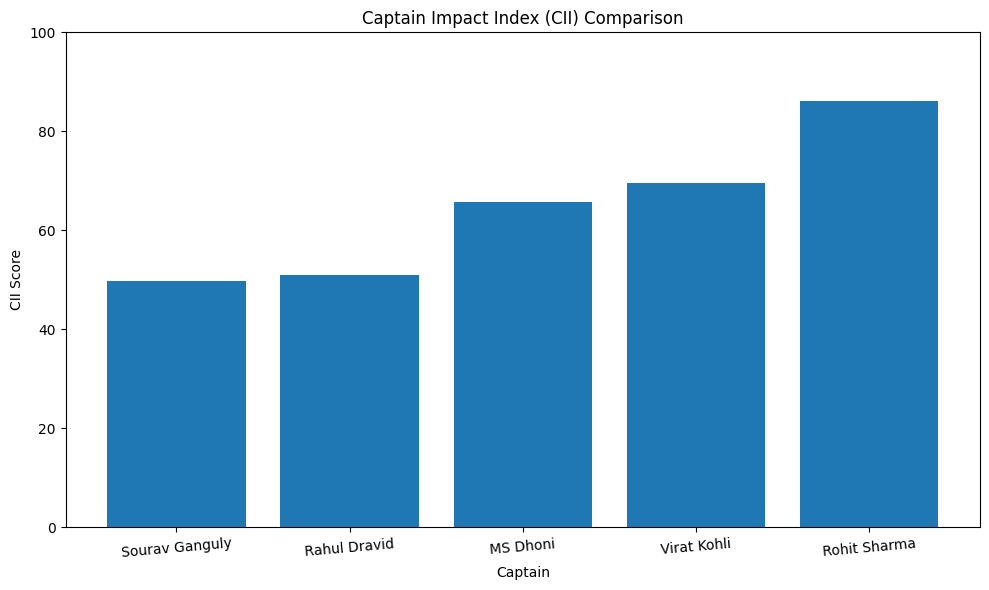

In [124]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    final_cii_df["Captain"],
    final_cii_df["CII"]
)

plt.title("Captain Impact Index (CII) Comparison")
plt.xlabel("Captain")
plt.ylabel("CII Score")
plt.ylim(0, 100)

plt.xticks(rotation=5)
plt.tight_layout()
plt.show()


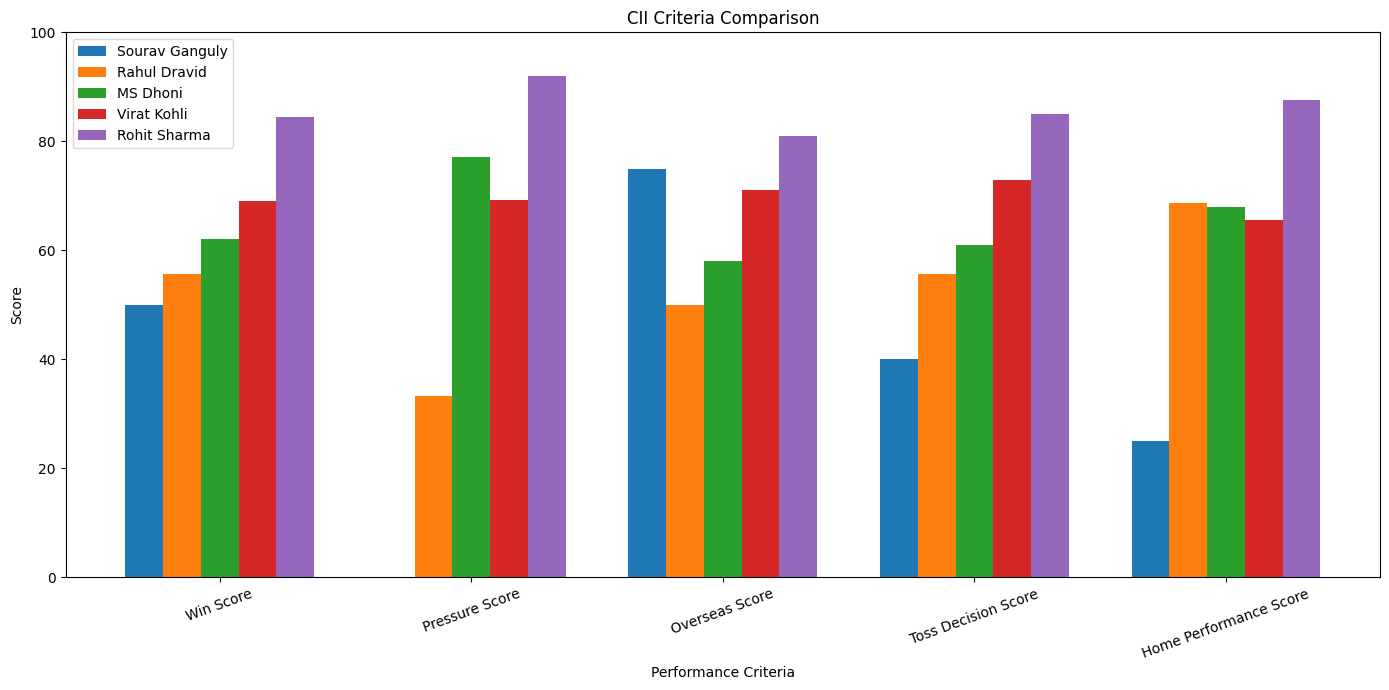

In [125]:
import matplotlib.pyplot as plt
import numpy as np

criteria = [
    "Win Score",
    "Pressure Score",
    "Overseas Score",
    "Toss Decision Score",
    "Home Performance Score"
]

x = np.arange(len(criteria))
width = 0.15

plt.figure(figsize=(14, 7))

for i, captain in enumerate(final_cii_df["Captain"]):
    values = [
        final_cii_df.loc[i, "Win_Score"],
        final_cii_df.loc[i, "Pressure_Score"],
        final_cii_df.loc[i, "Overseas_Score"],
        final_cii_df.loc[i, "Toss_Decision_Score"],
        final_cii_df.loc[i, "Home_Performance_Score"]
    ]

    plt.bar(
        x + (i - 2) * width,
        values,
        width,
        label=captain
    )

plt.title("CII Criteria Comparison")
plt.xlabel("Performance Criteria")
plt.ylabel("Score")
plt.xticks(x, criteria, rotation=20)
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()

/tmp/ipykernel_973/2789057411.py:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = cii_scores.loc[i, contribution_columns].fillna(0)


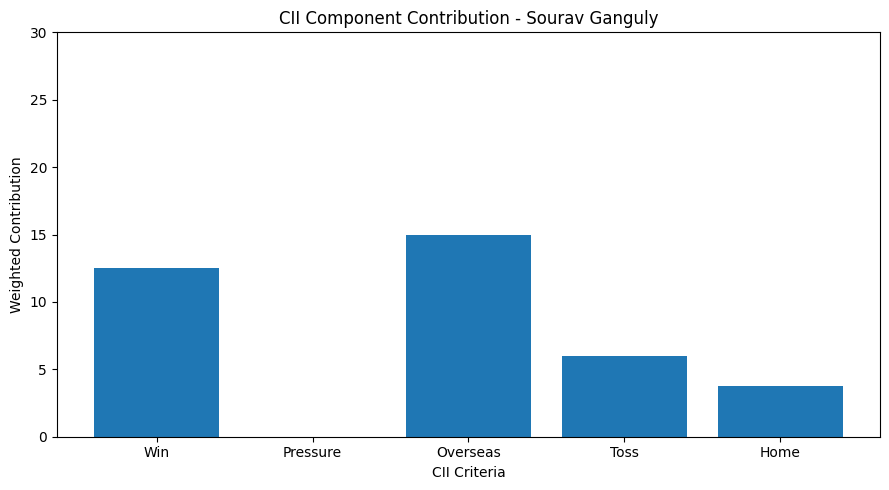

/tmp/ipykernel_973/2789057411.py:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = cii_scores.loc[i, contribution_columns].fillna(0)


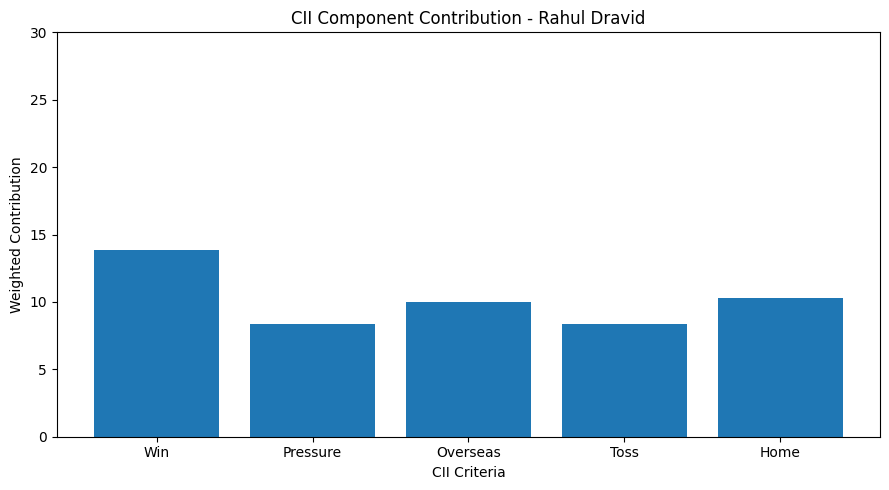

/tmp/ipykernel_973/2789057411.py:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = cii_scores.loc[i, contribution_columns].fillna(0)


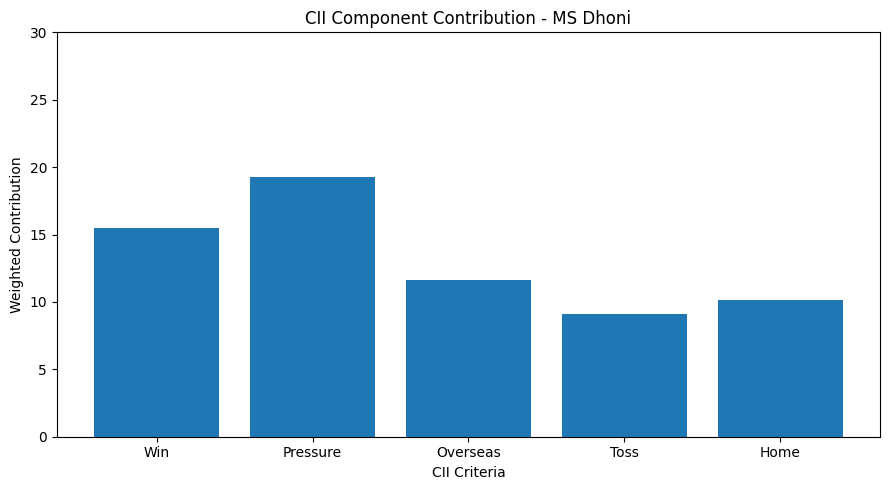

/tmp/ipykernel_973/2789057411.py:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = cii_scores.loc[i, contribution_columns].fillna(0)


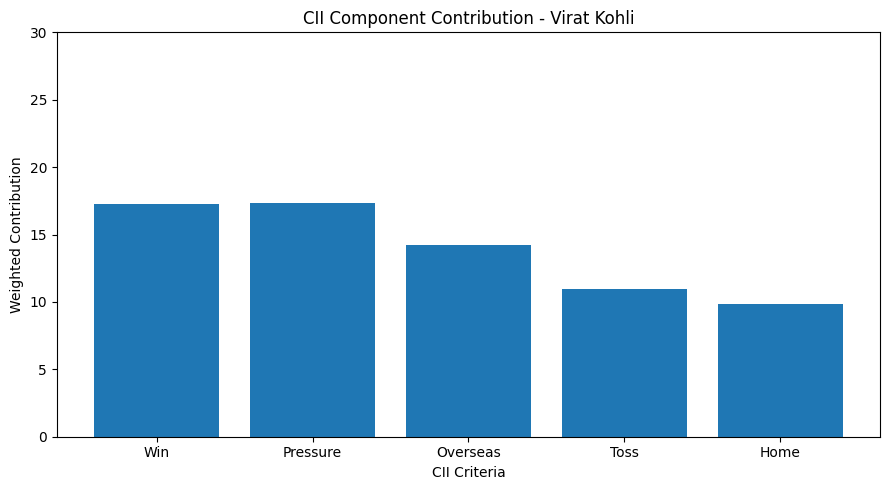

/tmp/ipykernel_973/2789057411.py:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = cii_scores.loc[i, contribution_columns].fillna(0)


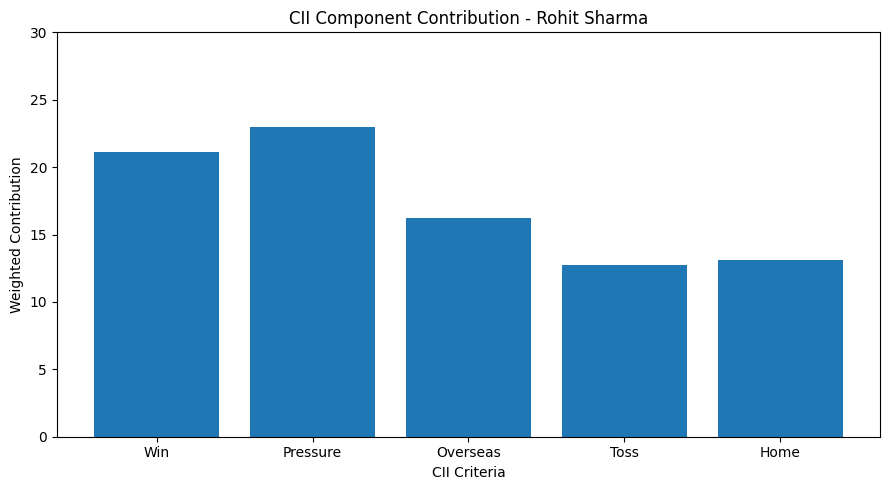

In [126]:
import matplotlib.pyplot as plt

contribution_columns = [
    "Win_Contribution",
    "Pressure_Contribution",
    "Overseas_Contribution",
    "Toss_Contribution",
    "Home_Contribution"
]

labels = [
    "Win",
    "Pressure",
    "Overseas",
    "Toss",
    "Home"
]

for i, captain in enumerate(cii_scores["Captain"]):
    values = cii_scores.loc[i, contribution_columns].fillna(0)

    plt.figure(figsize=(9, 5))

    plt.bar(labels, values)

    plt.title(f"CII Component Contribution - {captain}")
    plt.xlabel("CII Criteria")
    plt.ylabel("Weighted Contribution")
    plt.ylim(0, 30)

    plt.tight_layout()
    plt.show()

In [127]:
analysis_table = final_cii_df.sort_values(
    by="CII",
    ascending=False
).reset_index(drop=True)

print("FINAL CII ANALYSIS TABLE")
print("=" * 80)

print(analysis_table.to_string(index=False))

FINAL CII ANALYSIS TABLE
       Captain  Win_Score  Pressure_Score  Overseas_Score  Toss_Decision_Score  Home_Performance_Score   CII
  Rohit Sharma      84.44           92.00           80.95                85.00                   87.50 86.18
   Virat Kohli      69.05           69.23           71.15                72.97                   65.62 69.59
      MS Dhoni      62.02           77.14           58.06                60.91                   67.86 65.72
  Rahul Dravid      55.56           33.33           50.00                55.56                   68.75 50.87
Sourav Ganguly      50.00             NaN           75.00                40.00                   25.00 49.67


In [128]:
criteria_columns = [
    "Win_Score",
    "Pressure_Score",
    "Overseas_Score",
    "Toss_Decision_Score",
    "Home_Performance_Score",
    "CII"
]

for column in criteria_columns:
    valid_data = final_cii_df.dropna(subset=[column])

    highest = valid_data.loc[valid_data[column].idxmax()]
    lowest = valid_data.loc[valid_data[column].idxmin()]

    print(f"\n{column}")
    print("-" * 40)
    print(f"Highest: {highest['Captain']} ({highest[column]:.2f})")
    print(f"Lowest : {lowest['Captain']} ({lowest[column]:.2f})")


Win_Score
----------------------------------------
Highest: Rohit Sharma (84.44)
Lowest : Sourav Ganguly (50.00)

Pressure_Score
----------------------------------------
Highest: Rohit Sharma (92.00)
Lowest : Rahul Dravid (33.33)

Overseas_Score
----------------------------------------
Highest: Rohit Sharma (80.95)
Lowest : Rahul Dravid (50.00)

Toss_Decision_Score
----------------------------------------
Highest: Rohit Sharma (85.00)
Lowest : Sourav Ganguly (40.00)

Home_Performance_Score
----------------------------------------
Highest: Rohit Sharma (87.50)
Lowest : Sourav Ganguly (25.00)

CII
----------------------------------------
Highest: Rohit Sharma (86.18)
Lowest : Sourav Ganguly (49.67)


In [129]:
print("Number of captains:", final_cii_df["Captain"].nunique())
print("\nCaptains:")
print(final_cii_df["Captain"].tolist())

print("\nMissing values:")
print(final_cii_df.isnull().sum())

Number of captains: 5

Captains:
['Sourav Ganguly', 'Rahul Dravid', 'MS Dhoni', 'Virat Kohli', 'Rohit Sharma']

Missing values:
Captain                   0
Win_Score                 0
Pressure_Score            1
Overseas_Score            0
Toss_Decision_Score       0
Home_Performance_Score    0
CII                       0
dtype: int64


In [130]:
# Create final master CII dataset
master_cii_df = india_men_df.copy()

# Add CII score information to each captain's matches
master_cii_df = master_cii_df.merge(
    final_cii_df,
    on="Captain",
    how="left",
    suffixes=("", "_Final")
)

# Save the master dataset
master_cii_df.to_csv(
    "/content/CII_Master_Match_Level_Dataset.csv",
    index=False
)

print("Master dataset created successfully!")
print("Rows:", len(master_cii_df))
print("Columns:", len(master_cii_df.columns))

print("\nColumns:")
print(master_cii_df.columns.tolist())

Master dataset created successfully!
Rows: 474
Columns: 24

Columns:
['Match_ID', 'Date', 'Year', 'India', 'Opponent', 'Venue', 'City', 'Toss_Winner', 'Toss_Decision', 'Match_Winner', 'India_Result', 'Season', 'Match_Type', 'Location_Type', 'Captain', 'Event_Name', 'Match_Number', 'Pressure_Match', 'Win_Score', 'Pressure_Score', 'Overseas_Score', 'Toss_Decision_Score', 'Home_Performance_Score', 'CII']


In [131]:
print("Total rows:", len(master_cii_df))
print("Unique Match IDs:", master_cii_df["Match_ID"].nunique())
print("Duplicate Match IDs:", master_cii_df["Match_ID"].duplicated().sum())

print("\nCaptain-wise match count:")
print(master_cii_df["Captain"].value_counts())

Total rows: 474
Unique Match IDs: 474
Duplicate Match IDs: 0

Captain-wise match count:
Captain
MS Dhoni           223
Virat Kohli         87
Rahul Dravid        57
Rohit Sharma        47
Shikhar Dhawan      18
KL Rahul            12
Suresh Raina        11
Sourav Ganguly       8
Shubman Gill         6
Ajinkya Rahane       3
Virender Sehwag      2
Name: count, dtype: int64
